In [1]:
#Librarie's

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skimage.feature import local_binary_pattern, graycomatrix, graycoprops

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [2]:
#Path of the Image Dataset:

images_path = r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images"
masks_path = r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks"

In [27]:
# =========================
# MOBILE NET V2 - MEMORY EFFICIENT VERSION
# =========================

from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ---------------- CONFIG ----------------
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 224          # later try 192
BATCH_SIZE = 16         # keep lower for memory safety
EPOCHS_HEAD = 10
EPOCHS_FINE = 10
RANDOM_STATE = 42
MODEL_NAME = f"mobilenetv2_{IMG_SIZE}"

AUTOTUNE = tf.data.AUTOTUNE
EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

# ---------------- FILE HELPERS ----------------
def list_files(d: Path):
    return [p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS]

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(path)
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

# ---------------- BUILD DATAFRAME ----------------
img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems = sorted(set(img_by) & set(msk_by))

print(f"Matched pairs: {len(stems)}")

rows = []
for s in tqdm(stems, desc="Building dataframe"):
    mask = read_mask(msk_by[s])
    unique_values = np.unique(mask)

    # same binary logic you chose
    label = 1 if np.any(np.isin(unique_values, [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])
print(df["label"].value_counts())

# ---------------- SPLIT DATAFRAME ----------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

# ---------------- LIGHTWEIGHT WHITE-SPACE CROP ----------------
def crop_white_space_np(image, white_threshold=220):
    """
    Crop large white borders/background.
    Lighter than tile reconstruction and better for CNN memory/runtime.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < white_threshold

    if np.any(tissue_mask):
        coords = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        image = image[y_min:y_max+1, x_min:x_max+1]

    return image

# ---------------- TF PREPROCESS FUNCTION ----------------
def preprocess_image_tf(path, label):
    path = path.numpy().decode("utf-8")

    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # remove white space by cropping
    image = crop_white_space_np(image, white_threshold=220)

    # resize
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

    # normalize
    image = image.astype(np.float32) / 255.0

    return image, np.float32(label.numpy())

def tf_wrapper(path, label):
    image, label = tf.py_function(
        func=preprocess_image_tf,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())
    return image, label

# ---------------- DATA AUGMENTATION ----------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

# ---------------- DATASET BUILDER ----------------
def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values.astype(np.float32)
    ))

    if training:
        ds = ds.shuffle(len(dataframe), seed=RANDOM_STATE)

    ds = ds.map(tf_wrapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# ---------------- MODEL ----------------
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name=MODEL_NAME)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# ---------------- CALLBACKS ----------------
callbacks = [
    EarlyStopping(monitor="val_auc", patience=5, mode="max", restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ModelCheckpoint(f"{MODEL_NAME}_best.keras", monitor="val_auc", mode="max", save_best_only=True)
]

# ---------------- TRAIN HEAD ----------------
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks,
    verbose=1
)

# ---------------- FINE-TUNING ----------------
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks,
    verbose=1
)

# ---------------- EVALUATION ----------------
y_prob = model.predict(test_ds).ravel()
y_true = test_df["label"].values
y_pred = (y_prob >= 0.5).astype(int)

print("\nAccuracy:", accuracy_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))
print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification Report:\n", classification_report(y_true, y_pred, digits=3))

# ---------------- PARAMETER COUNT ----------------
trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])
total_params = trainable_params + non_trainable_params

print(f"\nTrainable params: {trainable_params:,}")
print(f"Non-trainable params: {non_trainable_params:,}")
print(f"Total params: {total_params:,}")

# ---------------- SAVE MODEL ----------------
model.save(f"{MODEL_NAME}_final.keras")

# ---------------- TFLITE EXPORT ----------------
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open(f"{MODEL_NAME}.tflite", "wb") as f:
    f.write(tflite_model)

# ---------------- QUANTIZED TFLITE EXPORT ----------------
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_q = converter_q.convert()

with open(f"{MODEL_NAME}_quant.tflite", "wb") as f:
    f.write(tflite_model_q)

# ---------------- FILE SIZE REPORT ----------------
keras_size = os.path.getsize(f"{MODEL_NAME}_final.keras") / (1024 * 1024)
tflite_size = os.path.getsize(f"{MODEL_NAME}.tflite") / (1024 * 1024)
tflite_q_size = os.path.getsize(f"{MODEL_NAME}_quant.tflite") / (1024 * 1024)

print(f"\nKeras model size: {keras_size:.2f} MB")
print(f"TFLite model size: {tflite_size:.2f} MB")
print(f"Quantized TFLite model size: {tflite_q_size:.2f} MB")

Matched pairs: 18783


Building dataframe: 100%|███████████████████████████████████████████████████████| 18783/18783 [01:28<00:00, 211.10it/s]


label
0    10725
1     8058
Name: count, dtype: int64
Train: (15026, 2)
Val: (1878, 2)
Test: (1879, 2)


Model: "mobilenetv2_224"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

...

Epoch 1/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 178s 186ms/step - accuracy: 0.7334 - auc: 0.7961 - loss: 0.5444 - val_accuracy: 0.6938 - val_auc: 0.8289 - val_loss: 0.6229 - learning_rate: 0.0010
Epoch 2/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 161s 171ms/step - accuracy: 0.7649 - auc: 0.8316 - loss: 0.5058 - val_accuracy: 0.6752 - val_auc: 0.8379 - val_loss: 0.6496 - learning_rate: 0.0010
Epoch 3/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 162s 172ms/step - accuracy: 0.7678 - auc: 0.8397 - loss: 0.4934 - val_accuracy: 0.7029 - val_auc: 0.8399 - val_loss: 0.6082 - learning_rate: 0.0010
Epoch 4/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 162s 173ms/step - accuracy: 0.7718 - auc: 0.8402 - loss: 0.4932 - val_accuracy: 0.7338 - val_auc: 0.8434 - val_loss: 0.5512 - learning_rate: 0.0010
Epoch 5/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 163s 173ms/step - accuracy: 0.7719 - auc: 0.8421 - loss: 0.4900 - val_accuracy: 0.7561 - val_auc: 0.8444 - val_loss: 0.5223 - learning_rate: 0.0010
Epoch 6/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 165s 175ms/step - ac

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpbasx_yvl\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpbasx_yvl'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_484')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2402699487248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699486480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699486864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699485904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699486672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699487440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699487056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699485712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699486288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699486096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpiya_lkj2\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpiya_lkj2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_484')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2402699487248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699486480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699486864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699485904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699486672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699487440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699487056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699485712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699486288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2402699486096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2

In [1]:
# =========================
# MOBILE NET V2 - MEMORY EFFICIENT VERSION
# =========================

from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ---------------- CONFIG ----------------
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 192          # later try 192
BATCH_SIZE = 16         # keep lower for memory safety
EPOCHS_HEAD = 10
EPOCHS_FINE = 10
RANDOM_STATE = 42
MODEL_NAME = f"mobilenetv2_{IMG_SIZE}"

AUTOTUNE = tf.data.AUTOTUNE
EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

# ---------------- FILE HELPERS ----------------
def list_files(d: Path):
    return [p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS]

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(path)
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

# ---------------- BUILD DATAFRAME ----------------
img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems = sorted(set(img_by) & set(msk_by))

print(f"Matched pairs: {len(stems)}")

rows = []
for s in tqdm(stems, desc="Building dataframe"):
    mask = read_mask(msk_by[s])
    unique_values = np.unique(mask)

    # same binary logic you chose
    label = 1 if np.any(np.isin(unique_values, [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])
print(df["label"].value_counts())

# ---------------- SPLIT DATAFRAME ----------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

# ---------------- LIGHTWEIGHT WHITE-SPACE CROP ----------------
def crop_white_space_np(image, white_threshold=220):
    """
    Crop large white borders/background.
    Lighter than tile reconstruction and better for CNN memory/runtime.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < white_threshold

    if np.any(tissue_mask):
        coords = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        image = image[y_min:y_max+1, x_min:x_max+1]

    return image

# ---------------- TF PREPROCESS FUNCTION ----------------
def preprocess_image_tf(path, label):
    path = path.numpy().decode("utf-8")

    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # remove white space by cropping
    image = crop_white_space_np(image, white_threshold=220)

    # resize
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

    # normalize
    image = image.astype(np.float32) / 255.0

    return image, np.float32(label.numpy())

def tf_wrapper(path, label):
    image, label = tf.py_function(
        func=preprocess_image_tf,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())
    return image, label

# ---------------- DATA AUGMENTATION ----------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

# ---------------- DATASET BUILDER ----------------
def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values.astype(np.float32)
    ))

    if training:
        ds = ds.shuffle(len(dataframe), seed=RANDOM_STATE)

    ds = ds.map(tf_wrapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# ---------------- MODEL ----------------
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name=MODEL_NAME)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# ---------------- CALLBACKS ----------------
callbacks = [
    EarlyStopping(monitor="val_auc", patience=5, mode="max", restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ModelCheckpoint(f"{MODEL_NAME}_best.keras", monitor="val_auc", mode="max", save_best_only=True)
]

# ---------------- TRAIN HEAD ----------------
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks,
    verbose=1
)

# ---------------- FINE-TUNING ----------------
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks,
    verbose=1
)

# ---------------- EVALUATION ----------------
y_prob = model.predict(test_ds).ravel()
y_true = test_df["label"].values
y_pred = (y_prob >= 0.5).astype(int)

print("\nAccuracy:", accuracy_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))
print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification Report:\n", classification_report(y_true, y_pred, digits=3))

# ---------------- PARAMETER COUNT ----------------
trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])
total_params = trainable_params + non_trainable_params

print(f"\nTrainable params: {trainable_params:,}")
print(f"Non-trainable params: {non_trainable_params:,}")
print(f"Total params: {total_params:,}")

# ---------------- SAVE MODEL ----------------
model.save(f"{MODEL_NAME}_final.keras")

# ---------------- TFLITE EXPORT ----------------
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open(f"{MODEL_NAME}.tflite", "wb") as f:
    f.write(tflite_model)

# ---------------- QUANTIZED TFLITE EXPORT ----------------
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_q = converter_q.convert()

with open(f"{MODEL_NAME}_quant.tflite", "wb") as f:
    f.write(tflite_model_q)

# ---------------- FILE SIZE REPORT ----------------
keras_size = os.path.getsize(f"{MODEL_NAME}_final.keras") / (1024 * 1024)
tflite_size = os.path.getsize(f"{MODEL_NAME}.tflite") / (1024 * 1024)
tflite_q_size = os.path.getsize(f"{MODEL_NAME}_quant.tflite") / (1024 * 1024)

print(f"\nKeras model size: {keras_size:.2f} MB")
print(f"TFLite model size: {tflite_size:.2f} MB")
print(f"Quantized TFLite model size: {tflite_q_size:.2f} MB")

Matched pairs: 18783


Building dataframe: 100%|███████████████████████████████████████████████████████| 18783/18783 [02:15<00:00, 139.09it/s]


label
0    10725
1     8058
Name: count, dtype: int64
Train: (15026, 2)
Val: (1878, 2)
Test: (1879, 2)
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 14s 1us/step


Model: "mobilenetv2_192"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_192 (Functional)    │ (None, 6, 6, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

...

Epoch 1/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 134s 138ms/step - accuracy: 0.7287 - auc: 0.7911 - loss: 0.5516 - val_accuracy: 0.7268 - val_auc: 0.8293 - val_loss: 0.5626 - learning_rate: 0.0010
Epoch 2/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 114s 122ms/step - accuracy: 0.7639 - auc: 0.8308 - loss: 0.5065 - val_accuracy: 0.7370 - val_auc: 0.8411 - val_loss: 0.5476 - learning_rate: 0.0010
Epoch 3/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 121s 128ms/step - accuracy: 0.7696 - auc: 0.8387 - loss: 0.4948 - val_accuracy: 0.7508 - val_auc: 0.8445 - val_loss: 0.5273 - learning_rate: 0.0010
Epoch 4/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 136s 145ms/step - accuracy: 0.7670 - auc: 0.8385 - loss: 0.4946 - val_accuracy: 0.7614 - val_auc: 0.8461 - val_loss: 0.5205 - learning_rate: 0.0010
Epoch 5/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 136s 144ms/step - accuracy: 0.7671 - auc: 0.8383 - loss: 0.4972 - val_accuracy: 0.7609 - val_auc: 0.8400 - val_loss: 0.5150 - learning_rate: 0.0010
Epoch 6/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 139s 148ms/step - ac

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpff5i01wb\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpff5i01wb'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1448428191568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436335824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436335632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428179664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436336208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436334672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436336784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436337744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436337360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436336016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpwha3xe5c\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpwha3xe5c'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1448428191568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436335824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436335632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428179664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436336208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436334672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436336784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436337744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436337360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448436336016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

In [2]:
# =========================
# MOBILE NET V3 SMALL - MEMORY EFFICIENT VERSION
# =========================

from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ---------------- CONFIG ----------------
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 224          # later try 192 in a separate run
BATCH_SIZE = 16         # reduce to 8 if needed
EPOCHS_HEAD = 10
EPOCHS_FINE = 10
RANDOM_STATE = 42
MODEL_NAME = f"mobilenetv3small_{IMG_SIZE}"

AUTOTUNE = tf.data.AUTOTUNE
EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

# ---------------- FILE HELPERS ----------------
def list_files(d: Path):
    return [p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS]

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(path)
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

# ---------------- BUILD DATAFRAME ----------------
img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems = sorted(set(img_by) & set(msk_by))

print(f"Matched pairs: {len(stems)}")

rows = []
for s in tqdm(stems, desc="Building dataframe"):
    mask = read_mask(msk_by[s])
    unique_values = np.unique(mask)

    # same binary logic you used earlier
    label = 1 if np.any(np.isin(unique_values, [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])
print(df["label"].value_counts())

# ---------------- SPLIT DATAFRAME ----------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

# ---------------- LIGHTWEIGHT WHITE-SPACE CROP ----------------
def crop_white_space_np(image, white_threshold=220):
    """
    Crop large white borders/background.
    Simpler and more memory-efficient than tile reconstruction for CNN training.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < white_threshold

    if np.any(tissue_mask):
        coords = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        image = image[y_min:y_max+1, x_min:x_max+1]

    return image

# ---------------- TF PREPROCESS FUNCTION ----------------
def preprocess_image_tf(path, label):
    path = path.numpy().decode("utf-8")

    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # crop white space
    image = crop_white_space_np(image, white_threshold=220)

    # resize
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

    # normalize
    image = image.astype(np.float32) / 255.0

    return image, np.float32(label.numpy())

def tf_wrapper(path, label):
    image, label = tf.py_function(
        func=preprocess_image_tf,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())
    return image, label

# ---------------- DATA AUGMENTATION ----------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

# ---------------- DATASET BUILDER ----------------
def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values.astype(np.float32)
    ))

    if training:
        ds = ds.shuffle(len(dataframe), seed=RANDOM_STATE)

    ds = ds.map(tf_wrapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# ---------------- MODEL ----------------
base_model = MobileNetV3Small(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name=MODEL_NAME)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# ---------------- CALLBACKS ----------------
callbacks = [
    EarlyStopping(monitor="val_auc", patience=5, mode="max", restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ModelCheckpoint(f"{MODEL_NAME}_best.keras", monitor="val_auc", mode="max", save_best_only=True)
]

# ---------------- TRAIN HEAD ----------------
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks,
    verbose=1
)

# ---------------- FINE-TUNING ----------------
base_model.trainable = True

# unfreeze only top part
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks,
    verbose=1
)

# ---------------- EVALUATION ----------------
y_prob = model.predict(test_ds).ravel()
y_true = test_df["label"].values
y_pred = (y_prob >= 0.5).astype(int)

print("\nAccuracy:", accuracy_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))
print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification Report:\n", classification_report(y_true, y_pred, digits=3))

# ---------------- PARAMETER COUNT ----------------
trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])
total_params = trainable_params + non_trainable_params

print(f"\nTrainable params: {trainable_params:,}")
print(f"Non-trainable params: {non_trainable_params:,}")
print(f"Total params: {total_params:,}")

# ---------------- SAVE MODEL ----------------
model.save(f"{MODEL_NAME}_final.keras")

# ---------------- TFLITE EXPORT ----------------
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open(f"{MODEL_NAME}.tflite", "wb") as f:
    f.write(tflite_model)

# ---------------- QUANTIZED TFLITE EXPORT ----------------
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_q = converter_q.convert()

with open(f"{MODEL_NAME}_quant.tflite", "wb") as f:
    f.write(tflite_model_q)

# ---------------- FILE SIZE REPORT ----------------
keras_size = os.path.getsize(f"{MODEL_NAME}_final.keras") / (1024 * 1024)
tflite_size = os.path.getsize(f"{MODEL_NAME}.tflite") / (1024 * 1024)
tflite_q_size = os.path.getsize(f"{MODEL_NAME}_quant.tflite") / (1024 * 1024)

print(f"\nKeras model size: {keras_size:.2f} MB")
print(f"TFLite model size: {tflite_size:.2f} MB")
print(f"Quantized TFLite model size: {tflite_q_size:.2f} MB")

Matched pairs: 18783


Building dataframe: 100%|███████████████████████████████████████████████████████| 18783/18783 [02:06<00:00, 148.73it/s]


label
0    10725
1     8058
Name: count, dtype: int64
Train: (15026, 2)
Val: (1878, 2)
Test: (1879, 2)
4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 14s 3us/step


Model: "mobilenetv3small_224"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ MobileNetV3Small (Functional)        │ (None, 7, 7, 576)           │         939,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 576)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 576)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             577 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

...

Epoch 1/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 88s 90ms/step - accuracy: 0.5960 - auc: 0.6012 - loss: 0.6675 - val_accuracy: 0.6608 - val_auc: 0.6990 - val_loss: 0.6423 - learning_rate: 0.0010
Epoch 2/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 70s 74ms/step - accuracy: 0.6376 - auc: 0.6690 - loss: 0.6430 - val_accuracy: 0.6081 - val_auc: 0.7004 - val_loss: 0.6566 - learning_rate: 0.0010
Epoch 3/10
939/940 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.6431 - auc: 0.6737 - loss: 0.6370
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
940/940 ━━━━━━━━━━━━━━━━━━━━ 70s 74ms/step - accuracy: 0.6467 - auc: 0.6787 - loss: 0.6349 - val_accuracy: 0.6278 - val_auc: 0.7007 - val_loss: 0.6458 - learning_rate: 0.0010
Epoch 4/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 73s 77ms/step - accuracy: 0.6523 - auc: 0.6894 - loss: 0.6290 - val_accuracy: 0.6251 - val_auc: 0.7013 - val_loss: 0.6485 - learning_rate: 5.0000e-04
Epoch 5/10
939/940 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.6483 - auc: 0.6842 

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpzziq5szw\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpzziq5szw'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_340')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1448428190032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428188688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428189456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428189072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428185616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428189840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428188880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428185808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428190224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428182736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpp12unyel\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpp12unyel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_340')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1448428190032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428188688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428189456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428189072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428185616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428189840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428188880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428185808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428190224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1448428182736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

In [3]:
# =========================
# MOBILE NET V3 SMALL - MEMORY EFFICIENT VERSION
# =========================

from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV3Small
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ---------------- CONFIG ----------------
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 192          # later try 192 in a separate run
BATCH_SIZE = 16         # reduce to 8 if needed
EPOCHS_HEAD = 10
EPOCHS_FINE = 10
RANDOM_STATE = 42
MODEL_NAME = f"mobilenetv3small_{IMG_SIZE}"

AUTOTUNE = tf.data.AUTOTUNE
EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

# ---------------- FILE HELPERS ----------------
def list_files(d: Path):
    return [p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS]

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(path)
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

# ---------------- BUILD DATAFRAME ----------------
img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems = sorted(set(img_by) & set(msk_by))

print(f"Matched pairs: {len(stems)}")

rows = []
for s in tqdm(stems, desc="Building dataframe"):
    mask = read_mask(msk_by[s])
    unique_values = np.unique(mask)

    # same binary logic you used earlier
    label = 1 if np.any(np.isin(unique_values, [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])
print(df["label"].value_counts())

# ---------------- SPLIT DATAFRAME ----------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

# ---------------- LIGHTWEIGHT WHITE-SPACE CROP ----------------
def crop_white_space_np(image, white_threshold=220):
    """
    Crop large white borders/background.
    Simpler and more memory-efficient than tile reconstruction for CNN training.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < white_threshold

    if np.any(tissue_mask):
        coords = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        image = image[y_min:y_max+1, x_min:x_max+1]

    return image

# ---------------- TF PREPROCESS FUNCTION ----------------
def preprocess_image_tf(path, label):
    path = path.numpy().decode("utf-8")

    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # crop white space
    image = crop_white_space_np(image, white_threshold=220)

    # resize
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

    # normalize
    image = image.astype(np.float32) / 255.0

    return image, np.float32(label.numpy())

def tf_wrapper(path, label):
    image, label = tf.py_function(
        func=preprocess_image_tf,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())
    return image, label

# ---------------- DATA AUGMENTATION ----------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

# ---------------- DATASET BUILDER ----------------
def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values.astype(np.float32)
    ))

    if training:
        ds = ds.shuffle(len(dataframe), seed=RANDOM_STATE)

    ds = ds.map(tf_wrapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# ---------------- MODEL ----------------
base_model = MobileNetV3Small(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name=MODEL_NAME)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# ---------------- CALLBACKS ----------------
callbacks = [
    EarlyStopping(monitor="val_auc", patience=5, mode="max", restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ModelCheckpoint(f"{MODEL_NAME}_best.keras", monitor="val_auc", mode="max", save_best_only=True)
]

# ---------------- TRAIN HEAD ----------------
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks,
    verbose=1
)

# ---------------- FINE-TUNING ----------------
base_model.trainable = True

# unfreeze only top part
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks,
    verbose=1
)

# ---------------- EVALUATION ----------------
y_prob = model.predict(test_ds).ravel()
y_true = test_df["label"].values
y_pred = (y_prob >= 0.5).astype(int)

print("\nAccuracy:", accuracy_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))
print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification Report:\n", classification_report(y_true, y_pred, digits=3))

# ---------------- PARAMETER COUNT ----------------
trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])
total_params = trainable_params + non_trainable_params

print(f"\nTrainable params: {trainable_params:,}")
print(f"Non-trainable params: {non_trainable_params:,}")
print(f"Total params: {total_params:,}")

# ---------------- SAVE MODEL ----------------
model.save(f"{MODEL_NAME}_final.keras")

# ---------------- TFLITE EXPORT ----------------
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open(f"{MODEL_NAME}.tflite", "wb") as f:
    f.write(tflite_model)

# ---------------- QUANTIZED TFLITE EXPORT ----------------
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_q = converter_q.convert()

with open(f"{MODEL_NAME}_quant.tflite", "wb") as f:
    f.write(tflite_model_q)

# ---------------- FILE SIZE REPORT ----------------
keras_size = os.path.getsize(f"{MODEL_NAME}_final.keras") / (1024 * 1024)
tflite_size = os.path.getsize(f"{MODEL_NAME}.tflite") / (1024 * 1024)
tflite_q_size = os.path.getsize(f"{MODEL_NAME}_quant.tflite") / (1024 * 1024)

print(f"\nKeras model size: {keras_size:.2f} MB")
print(f"TFLite model size: {tflite_size:.2f} MB")
print(f"Quantized TFLite model size: {tflite_q_size:.2f} MB")

Matched pairs: 18783


Building dataframe: 100%|███████████████████████████████████████████████████████| 18783/18783 [02:01<00:00, 155.05it/s]
C:\Users\viraj\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\applications\mobilenet_v3.py:452: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


label
0    10725
1     8058
Name: count, dtype: int64
Train: (15026, 2)
Val: (1878, 2)
Test: (1879, 2)


Model: "mobilenetv3small_192"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)           │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ MobileNetV3Small (Functional)        │ (None, 6, 6, 576)           │         939,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 576)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 576)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │             577 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

...

Epoch 1/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 104s 107ms/step - accuracy: 0.5947 - auc: 0.6063 - loss: 0.6659 - val_accuracy: 0.6544 - val_auc: 0.6990 - val_loss: 0.6432 - learning_rate: 0.0010
Epoch 2/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 98s 104ms/step - accuracy: 0.6329 - auc: 0.6584 - loss: 0.6458 - val_accuracy: 0.6129 - val_auc: 0.6996 - val_loss: 0.6563 - learning_rate: 0.0010
Epoch 3/10
939/940 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.6335 - auc: 0.6714 - loss: 0.6386
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
940/940 ━━━━━━━━━━━━━━━━━━━━ 97s 103ms/step - accuracy: 0.6406 - auc: 0.6779 - loss: 0.6359 - val_accuracy: 0.6347 - val_auc: 0.7001 - val_loss: 0.6455 - learning_rate: 0.0010
Epoch 4/10
940/940 ━━━━━━━━━━━━━━━━━━━━ 101s 107ms/step - accuracy: 0.6485 - auc: 0.6819 - loss: 0.6324 - val_accuracy: 0.6337 - val_auc: 0.7006 - val_loss: 0.6468 - learning_rate: 5.0000e-04
Epoch 5/10
939/940 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.6416 - auc: 0

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpbbx5q940\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpbbx5q940'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_526')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1449775329744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775329360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775328784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775329552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775328016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775330320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775329168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775328592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775329936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775327056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpnbtidz_x\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpnbtidz_x'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_526')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1449775329744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775329360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775328784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775329552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775328016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775330320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775329168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775328592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775329936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1449775327056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

In [ ]:
# =========================
# MOBILE NET V2 - IMPROVED EIS VERSION
# =========================

from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ---------------- CONFIG ----------------
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 192                  # try 192 first, then 224 separately
BATCH_SIZE = 16                 # reduce to 8 if memory is still tight
EPOCHS_HEAD = 15
EPOCHS_FINE = 15
RANDOM_STATE = 42
MODEL_NAME = f"mobilenetv2_improved_{IMG_SIZE}"

AUTOTUNE = tf.data.AUTOTUNE
EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

# White-space removal config
TILE_SIZE = 32
OVERLAP = 0.5
WHITE_THRESHOLD = 220
TISSUE_THRESHOLD = 0.20

# ---------------- FILE HELPERS ----------------
def list_files(d: Path):
    return [p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS]

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(path)
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

# ---------------- BUILD DATAFRAME ----------------
img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems = sorted(set(img_by) & set(msk_by))

print(f"Matched pairs: {len(stems)}")

rows = []
for s in tqdm(stems, desc="Building dataframe"):
    mask = read_mask(msk_by[s])
    unique_values = np.unique(mask)

    # keep your original binary logic
    label = 1 if np.any(np.isin(unique_values, [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])
print(df["label"].value_counts())

# ---------------- SPLITS ----------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

# ---------------- CLASS WEIGHTS ----------------
classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)
class_weight = {0: weights[0], 1: weights[1]}
print("Class weights:", class_weight)

# ---------------- WHITE-SPACE REMOVAL USING 32x32 BLOCKS ----------------
def remove_white_tiles_and_reconstruct(image,
                                       tile_size=TILE_SIZE,
                                       overlap=OVERLAP,
                                       white_threshold=WHITE_THRESHOLD,
                                       tissue_threshold=TISSUE_THRESHOLD):
    """
    Divide image into 32x32 tiles with overlap, remove mostly white tiles,
    and reconstruct the remaining tissue-focused image.
    """
    h, w, _ = image.shape
    step = int(tile_size * (1 - overlap))
    if step <= 0:
        step = tile_size // 2

    canvas = np.ones_like(image, dtype=np.float32) * 255.0
    count_map = np.zeros((h, w), dtype=np.float32)

    for y in range(0, h - tile_size + 1, step):
        for x in range(0, w - tile_size + 1, step):
            tile = image[y:y+tile_size, x:x+tile_size]
            gray_tile = cv2.cvtColor(tile, cv2.COLOR_RGB2GRAY)

            white_ratio = np.mean(gray_tile > white_threshold)
            tissue_ratio = 1.0 - white_ratio

            # keep only tissue-rich blocks
            if tissue_ratio >= tissue_threshold:
                canvas[y:y+tile_size, x:x+tile_size] += tile.astype(np.float32) - 255.0
                count_map[y:y+tile_size, x:x+tile_size] += 1.0

    valid = count_map > 0
    output = np.ones_like(image, dtype=np.float32) * 255.0

    for c in range(3):
        output[:, :, c][valid] = canvas[:, :, c][valid] / count_map[valid]

    output = np.clip(output, 0, 255).astype(np.uint8)

    # crop to non-white area after reconstruction
    gray = cv2.cvtColor(output, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < white_threshold
    if np.any(tissue_mask):
        coords = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        output = output[y_min:y_max+1, x_min:x_max+1]

    return output

# ---------------- TF PREPROCESS ----------------
def preprocess_image_tf(path, label):
    path = path.numpy().decode("utf-8")

    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # 32x32 block white-space removal
    image = remove_white_tiles_and_reconstruct(image)

    # resize after cleaning
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

    # MobileNetV2 preprocess
    image = image.astype(np.float32)
    image = preprocess_input(image)

    return image, np.float32(label.numpy())

def tf_wrapper(path, label):
    image, label = tf.py_function(
        func=preprocess_image_tf,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())
    return image, label

# ---------------- AUGMENTATION ----------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.12),
    layers.RandomContrast(0.15),
    layers.RandomTranslation(0.05, 0.05),
], name="data_augmentation")

# ---------------- DATASET BUILDER ----------------
def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values.astype(np.float32)
    ))

    if training:
        ds = ds.shuffle(len(dataframe), seed=RANDOM_STATE)

    ds = ds.map(tf_wrapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# ---------------- FOCAL LOSS ----------------
def binary_focal_loss(alpha=0.25, gamma=2.0):
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)

        pt = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)
        alpha_t = tf.where(tf.equal(y_true, 1), alpha, 1 - alpha)

        loss = -alpha_t * tf.pow(1.0 - pt, gamma) * tf.math.log(pt)
        return tf.reduce_mean(loss)
    return loss_fn

# ---------------- MODEL ----------------
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(
    1,
    activation="sigmoid",
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

model = models.Model(inputs, outputs, name=MODEL_NAME)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=binary_focal_loss(alpha=0.35, gamma=2.0),
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# ---------------- CALLBACKS ----------------
callbacks = [
    EarlyStopping(monitor="val_auc", patience=5, mode="max", restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ModelCheckpoint(f"{MODEL_NAME}_best.keras", monitor="val_auc", mode="max", save_best_only=True)
]

# ---------------- TRAIN HEAD ----------------
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

# ---------------- FINE-TUNING ----------------
base_model.trainable = True

# unfreeze more top layers than before
for layer in base_model.layers[:-50]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=binary_focal_loss(alpha=0.35, gamma=2.0),
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

# ---------------- EVALUATION ----------------
y_prob = model.predict(test_ds).ravel()
y_true = test_df["label"].values

print("\nROC-AUC:", roc_auc_score(y_true, y_prob))

for th in [0.50, 0.45, 0.40, 0.35]:
    y_pred = (y_prob >= th).astype(int)
    print(f"\n================ Threshold = {th} ================")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))
    print("Classification Report:\n", classification_report(y_true, y_pred, digits=3))

# choose one final threshold if needed
FINAL_THRESHOLD = 0.45
y_pred_final = (y_prob >= FINAL_THRESHOLD).astype(int)

print(f"\nFinal chosen threshold: {FINAL_THRESHOLD}")
print("Final Accuracy:", accuracy_score(y_true, y_pred_final))
print("Final Confusion Matrix:\n", confusion_matrix(y_true, y_pred_final))
print("Final Classification Report:\n", classification_report(y_true, y_pred_final, digits=3))

# ---------------- PARAMETER COUNT ----------------
trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])
total_params = trainable_params + non_trainable_params

print(f"\nTrainable params: {trainable_params:,}")
print(f"Non-trainable params: {non_trainable_params:,}")
print(f"Total params: {total_params:,}")

# ---------------- SAVE MODEL ----------------
model.save(f"{MODEL_NAME}_final.keras")

# ---------------- TFLITE EXPORT ----------------
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open(f"{MODEL_NAME}.tflite", "wb") as f:
    f.write(tflite_model)

# ---------------- QUANTIZED TFLITE EXPORT ----------------
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_q = converter_q.convert()

with open(f"{MODEL_NAME}_quant.tflite", "wb") as f:
    f.write(tflite_model_q)

# ---------------- FILE SIZE REPORT ----------------
keras_size = os.path.getsize(f"{MODEL_NAME}_final.keras") / (1024 * 1024)
tflite_size = os.path.getsize(f"{MODEL_NAME}.tflite") / (1024 * 1024)
tflite_q_size = os.path.getsize(f"{MODEL_NAME}_quant.tflite") / (1024 * 1024)

print(f"\nKeras model size: {keras_size:.2f} MB")
print(f"TFLite model size: {tflite_size:.2f} MB")
print(f"Quantized TFLite model size: {tflite_q_size:.2f} MB")

Matched pairs: 18783


Building dataframe: 100%|███████████████████████████████████████████████████████| 18783/18783 [01:00<00:00, 309.65it/s]


label
0    10725
1     8058
Name: count, dtype: int64
Train: (15026, 2)
Val: (1878, 2)
Test: (1879, 2)
Class weights: {0: np.float64(0.8756410256410256), 1: np.float64(1.1655290102389078)}


Model: "mobilenetv2_improved_192"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)          │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_192 (Functional)    │ (None, 6, 6, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 960s 1s/step - accuracy: 0.5688 - auc: 0.5659 - loss: 0.1012 - val_accuracy: 0.5836 - val_auc: 0.5495 - val_loss: 0.0920 - learning_rate: 0.0010
Epoch 2/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 955s 1s/step - accuracy: 0.5843 - auc: 0.5951 - loss: 0.0837 - val_accuracy: 0.5847 - val_auc: 0.5795 - val_loss: 0.0853 - learning_rate: 0.0010
Epoch 3/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 938s 998ms/step - accuracy: 0.5849 - auc: 0.6003 - loss: 0.0832 - val_accuracy: 0.5756 - val_auc: 0.6014 - val_loss: 0.0946 - learning_rate: 0.0010
Epoch 4/15
939/940 ━━━━━━━━━━━━━━━━━━━━ 0s 889ms/step - accuracy: 0.5817 - auc: 0.5935 - loss: 0.0830
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
940/940 ━━━━━━━━━━━━━━━━━━━━ 940s 999ms/step - accuracy: 0.5821 - auc: 0.5972 - loss: 0.0832 - val_accuracy: 0.5485 - val_auc: 0.4992 - val_loss: 0.0915 - learning_rate: 0.0010
Epoch 5/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 944s 1s/step - accuracy: 0.5936 - auc: 0.6164 -


KeyboardInterrupt



In [2]:
# ==========================================
# MOBILENETV2 IMPROVED (SAFE TF.KERAS STYLE)
# ==========================================

from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

# SAFE IMPORT STYLE
layers = tf.keras.layers
models = tf.keras.models
regularizers = tf.keras.regularizers
callbacks = tf.keras.callbacks
applications = tf.keras.applications

MobileNetV2 = applications.MobileNetV2
preprocess_input = applications.mobilenet_v2.preprocess_input

# ---------------- CONFIG ----------------

IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 192
BATCH_SIZE = 16
EPOCHS_HEAD = 15
EPOCHS_FINE = 15

MODEL_NAME = f"mobilenetv2_eis_{IMG_SIZE}"

AUTOTUNE = tf.data.AUTOTUNE

# white-space removal config
TILE_SIZE = 32
WHITE_THRESHOLD = 220
TISSUE_THRESHOLD = 0.20
OVERLAP = 0.5

EXTS = {".png",".jpg",".jpeg",".tif",".bmp"}

# ----------------------------------------
# FILE UTILITIES
# ----------------------------------------

def list_files(d):
    return [p for p in d.rglob("*") if p.suffix.lower() in EXTS]

def by_stem(paths):
    m={}
    for p in paths:
        m.setdefault(p.stem,p)
    return m

def read_mask(path):

    m=cv2.imread(str(path),cv2.IMREAD_UNCHANGED)

    if m.ndim==3:
        m=cv2.cvtColor(m,cv2.COLOR_BGR2GRAY)

    return m

# ----------------------------------------
# BUILD DATAFRAME
# ----------------------------------------

img_by=by_stem(list_files(IMAGES_DIR))
msk_by=by_stem(list_files(MASKS_DIR))

stems=sorted(set(img_by)&set(msk_by))

rows=[]

for s in tqdm(stems):

    mask=read_mask(msk_by[s])

    label=1 if np.any(np.isin(np.unique(mask),[1,2,3])) else 0

    rows.append([str(img_by[s]),label])

df=pd.DataFrame(rows,columns=["image_path","label"])

print(df.label.value_counts())

# ----------------------------------------
# TRAIN / VAL / TEST SPLIT
# ----------------------------------------

train_df,temp_df=train_test_split(df,test_size=0.2,stratify=df.label)

val_df,test_df=train_test_split(temp_df,test_size=0.5,stratify=temp_df.label)

print("Train:",len(train_df))
print("Val:",len(val_df))
print("Test:",len(test_df))

# ----------------------------------------
# CLASS WEIGHTS
# ----------------------------------------

classes=np.array([0,1])

weights=compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df.label.values
)

class_weight={0:weights[0],1:weights[1]}

print("Class weights:",class_weight)

# ----------------------------------------
# WHITE SPACE REMOVAL (32x32 BLOCKS)
# ----------------------------------------

def remove_white_tiles(image):

    h,w,_=image.shape

    step=int(TILE_SIZE*(1-OVERLAP))

    canvas=np.ones_like(image,dtype=np.float32)*255
    count=np.zeros((h,w))

    for y in range(0,h-TILE_SIZE+1,step):
        for x in range(0,w-TILE_SIZE+1,step):

            tile=image[y:y+TILE_SIZE,x:x+TILE_SIZE]

            gray=cv2.cvtColor(tile,cv2.COLOR_RGB2GRAY)

            white_ratio=np.mean(gray>WHITE_THRESHOLD)

            tissue_ratio=1-white_ratio

            if tissue_ratio>=TISSUE_THRESHOLD:

                canvas[y:y+TILE_SIZE,x:x+TILE_SIZE]+=tile-255
                count[y:y+TILE_SIZE,x:x+TILE_SIZE]+=1

    valid=count>0

    out=np.ones_like(image,dtype=np.float32)*255

    for c in range(3):
        out[:,:,c][valid]=canvas[:,:,c][valid]/count[valid]

    out=np.clip(out,0,255).astype(np.uint8)

    return out

# ----------------------------------------
# TF PREPROCESS FUNCTION
# ----------------------------------------

def preprocess_image(path,label):

    path=path.numpy().decode("utf-8")

    img=cv2.imread(path)

    img=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

    img=remove_white_tiles(img)

    img=cv2.resize(img,(IMG_SIZE,IMG_SIZE))

    img=img.astype(np.float32)

    img=preprocess_input(img)

    return img,np.float32(label.numpy())

def tf_wrapper(path,label):

    img,label=tf.py_function(
        preprocess_image,
        [path,label],
        [tf.float32,tf.float32]
    )

    img.set_shape((IMG_SIZE,IMG_SIZE,3))

    label.set_shape(())

    return img,label

# ----------------------------------------
# DATASET BUILDER
# ----------------------------------------

def make_dataset(dataframe,training=False):

    ds=tf.data.Dataset.from_tensor_slices(
        (dataframe.image_path.values,
         dataframe.label.values.astype(np.float32))
    )

    if training:
        ds=ds.shuffle(len(dataframe))

    ds=ds.map(tf_wrapper,num_parallel_calls=AUTOTUNE)

    ds=ds.batch(BATCH_SIZE)

    ds=ds.prefetch(AUTOTUNE)

    return ds

train_ds=make_dataset(train_df,True)
val_ds=make_dataset(val_df)
test_ds=make_dataset(test_df)

# ----------------------------------------
# DATA AUGMENTATION
# ----------------------------------------

augmentation=tf.keras.Sequential([

layers.RandomFlip("horizontal"),

layers.RandomRotation(0.08),

layers.RandomZoom(0.12),

layers.RandomContrast(0.15),

layers.RandomTranslation(0.05,0.05)

])

# ----------------------------------------
# FOCAL LOSS
# ----------------------------------------

def focal_loss(alpha=0.35,gamma=2):

    def loss(y_true,y_pred):

        y_pred=tf.clip_by_value(y_pred,1e-7,1-1e-7)

        pt=tf.where(tf.equal(y_true,1),y_pred,1-y_pred)

        loss=-alpha*(1-pt)**gamma*tf.math.log(pt)

        return tf.reduce_mean(loss)

    return loss

# ----------------------------------------
# MODEL
# ----------------------------------------

base_model=MobileNetV2(
    input_shape=(IMG_SIZE,IMG_SIZE,3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable=False

inputs=layers.Input(shape=(IMG_SIZE,IMG_SIZE,3))

x=augmentation(inputs)

x=base_model(x,training=False)

x=layers.GlobalAveragePooling2D()(x)

x=layers.Dropout(0.3)(x)

outputs=layers.Dense(
    1,
    activation="sigmoid",
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

model=models.Model(inputs,outputs)

model.compile(

optimizer=tf.keras.optimizers.Adam(1e-3),

loss=focal_loss(),

metrics=["accuracy",tf.keras.metrics.AUC(name="auc")]

)

model.summary()

# ----------------------------------------
# CALLBACKS
# ----------------------------------------

callback_list=[

callbacks.EarlyStopping(
monitor="val_auc",
patience=5,
restore_best_weights=True
),

callbacks.ReduceLROnPlateau(
monitor="val_loss",
factor=0.5,
patience=2
),

callbacks.ModelCheckpoint(
f"{MODEL_NAME}.keras",
monitor="val_auc",
mode="max",
save_best_only=True
)

]

# ----------------------------------------
# TRAIN HEAD
# ----------------------------------------

model.fit(

train_ds,
validation_data=val_ds,
epochs=EPOCHS_HEAD,
class_weight=class_weight,
callbacks=callback_list

)

# ----------------------------------------
# FINE TUNE
# ----------------------------------------

base_model.trainable=True

for layer in base_model.layers[:-70]:
    layer.trainable=False

model.compile(

optimizer=tf.keras.optimizers.Adam(1e-5),

loss=focal_loss(),

metrics=["accuracy",tf.keras.metrics.AUC(name="auc")]

)

model.fit(

train_ds,
validation_data=val_ds,
epochs=EPOCHS_FINE,
class_weight=class_weight,
callbacks=callback_list

)

# ----------------------------------------
# EVALUATION
# ----------------------------------------

y_prob=model.predict(test_ds).ravel()

y_true=test_df.label.values

print("ROC-AUC:",roc_auc_score(y_true,y_prob))

for th in [0.5,0.45,0.40,0.35]:

    y_pred=(y_prob>=th).astype(int)

    print("\nThreshold:",th)

    print("Accuracy:",accuracy_score(y_true,y_pred))

    print(confusion_matrix(y_true,y_pred))

    print(classification_report(y_true,y_pred,digits=3))

# ----------------------------------------
# SAVE MODEL
# ----------------------------------------

model.save(f"{MODEL_NAME}_final.keras")

# ----------------------------------------
# TFLITE CONVERSION
# ----------------------------------------

converter=tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model=converter.convert()

open(f"{MODEL_NAME}.tflite","wb").write(tflite_model)

# ----------------------------------------
# QUANTIZATION
# ----------------------------------------

converter=tf.lite.TFLiteConverter.from_keras_model(model)

converter.optimizations=[tf.lite.Optimize.DEFAULT]

tflite_quant=converter.convert()

open(f"{MODEL_NAME}_quant.tflite","wb").write(tflite_quant)

# ----------------------------------------
# MODEL SIZE REPORT
# ----------------------------------------

keras_size=os.path.getsize(f"{MODEL_NAME}_final.keras")/(1024*1024)
tflite_size=os.path.getsize(f"{MODEL_NAME}.tflite")/(1024*1024)
quant_size=os.path.getsize(f"{MODEL_NAME}_quant.tflite")/(1024*1024)

print("\nModel Sizes")

print("Keras:",keras_size,"MB")
print("TFLite:",tflite_size,"MB")
print("Quantized:",quant_size,"MB")

100%|███████████████████████████████████████████████████████████████████████████| 18783/18783 [00:53<00:00, 349.41it/s]


label
0    10725
1     8058
Name: count, dtype: int64
Train: 15026
Val: 1878
Test: 1879
Class weights: {0: np.float64(0.8756410256410256), 1: np.float64(1.1655290102389078)}


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_1 (Sequential)            │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_192 (Functional)    │ (None, 6, 6, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 877s 929ms/step - accuracy: 0.6843 - auc: 0.7317 - loss: 0.0650 - val_accuracy: 0.7199 - val_auc: 0.8173 - val_loss: 0.0492 - learning_rate: 0.0010
Epoch 2/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 840s 893ms/step - accuracy: 0.7265 - auc: 0.7897 - loss: 0.0514 - val_accuracy: 0.6986 - val_auc: 0.8213 - val_loss: 0.0544 - learning_rate: 0.0010
Epoch 3/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 834s 887ms/step - accuracy: 0.7320 - auc: 0.7989 - loss: 0.0502 - val_accuracy: 0.7396 - val_auc: 0.8129 - val_loss: 0.0497 - learning_rate: 0.0010
Epoch 4/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 836s 889ms/step - accuracy: 0.7403 - auc: 0.8069 - loss: 0.0486 - val_accuracy: 0.7050 - val_auc: 0.8244 - val_loss: 0.0527 - learning_rate: 5.0000e-04
Epoch 5/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 836s 889ms/step - accuracy: 0.7464 - auc: 0.8091 - loss: 0.0482 - val_accuracy: 0.7300 - val_auc: 0.8426 - val_loss: 0.0496 - learning_rate: 5.0000e-04
Epoch 6/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 845s 899ms/s

KeyboardInterrupt: 

In [3]:
# =========================
# MOBILE NET V2 - MEMORY EFFICIENT VERSION
# =========================

from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ---------------- CONFIG ----------------
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 192          # later try 192
BATCH_SIZE = 16         # keep lower for memory safety
EPOCHS_HEAD = 15
EPOCHS_FINE = 15
RANDOM_STATE = 42
MODEL_NAME = f"mobilenetv2_{IMG_SIZE}"

AUTOTUNE = tf.data.AUTOTUNE
EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

# ---------------- FILE HELPERS ----------------
def list_files(d: Path):
    return [p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS]

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(path)
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

# ---------------- BUILD DATAFRAME ----------------
img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems = sorted(set(img_by) & set(msk_by))

print(f"Matched pairs: {len(stems)}")

rows = []
for s in tqdm(stems, desc="Building dataframe"):
    mask = read_mask(msk_by[s])
    unique_values = np.unique(mask)

    # same binary logic you chose
    label = 1 if np.any(np.isin(unique_values, [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])
print(df["label"].value_counts())

# ---------------- SPLIT DATAFRAME ----------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

# ---------------- LIGHTWEIGHT WHITE-SPACE CROP ----------------
def crop_white_space_np(image, white_threshold=220):
    """
    Crop large white borders/background.
    Lighter than tile reconstruction and better for CNN memory/runtime.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < white_threshold

    if np.any(tissue_mask):
        coords = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        image = image[y_min:y_max+1, x_min:x_max+1]

    return image

# ---------------- TF PREPROCESS FUNCTION ----------------
def preprocess_image_tf(path, label):
    path = path.numpy().decode("utf-8")

    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # remove white space by cropping
    image = crop_white_space_np(image, white_threshold=220)

    # resize
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

    # normalize
    image = image.astype(np.float32) / 255.0

    return image, np.float32(label.numpy())

def tf_wrapper(path, label):
    image, label = tf.py_function(
        func=preprocess_image_tf,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())
    return image, label

# ---------------- DATA AUGMENTATION ----------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

# ---------------- DATASET BUILDER ----------------
def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values.astype(np.float32)
    ))

    if training:
        ds = ds.shuffle(len(dataframe), seed=RANDOM_STATE)

    ds = ds.map(tf_wrapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# ---------------- MODEL ----------------
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name=MODEL_NAME)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# ---------------- CALLBACKS ----------------
callbacks = [
    EarlyStopping(monitor="val_auc", patience=5, mode="max", restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ModelCheckpoint(f"{MODEL_NAME}_best.keras", monitor="val_auc", mode="max", save_best_only=True)
]

# ---------------- TRAIN HEAD ----------------
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks,
    verbose=1
)

# ---------------- FINE-TUNING ----------------
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks,
    verbose=1
)

# ---------------- EVALUATION ----------------
y_prob = model.predict(test_ds).ravel()
y_true = test_df["label"].values
y_pred = (y_prob >= 0.5).astype(int)

print("\nAccuracy:", accuracy_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))
print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification Report:\n", classification_report(y_true, y_pred, digits=3))

# ---------------- PARAMETER COUNT ----------------
trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])
total_params = trainable_params + non_trainable_params

print(f"\nTrainable params: {trainable_params:,}")
print(f"Non-trainable params: {non_trainable_params:,}")
print(f"Total params: {total_params:,}")

# ---------------- SAVE MODEL ----------------
model.save(f"{MODEL_NAME}_final.keras")

# ---------------- TFLITE EXPORT ----------------
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open(f"{MODEL_NAME}.tflite", "wb") as f:
    f.write(tflite_model)

# ---------------- QUANTIZED TFLITE EXPORT ----------------
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_q = converter_q.convert()

with open(f"{MODEL_NAME}_quant.tflite", "wb") as f:
    f.write(tflite_model_q)

# ---------------- FILE SIZE REPORT ----------------
keras_size = os.path.getsize(f"{MODEL_NAME}_final.keras") / (1024 * 1024)
tflite_size = os.path.getsize(f"{MODEL_NAME}.tflite") / (1024 * 1024)
tflite_q_size = os.path.getsize(f"{MODEL_NAME}_quant.tflite") / (1024 * 1024)

print(f"\nKeras model size: {keras_size:.2f} MB")
print(f"TFLite model size: {tflite_size:.2f} MB")
print(f"Quantized TFLite model size: {tflite_q_size:.2f} MB")

Matched pairs: 18783


Building dataframe: 100%|███████████████████████████████████████████████████████| 18783/18783 [00:53<00:00, 348.29it/s]


label
0    10725
1     8058
Name: count, dtype: int64
Train: (15026, 2)
Val: (1878, 2)
Test: (1879, 2)


Model: "mobilenetv2_192"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)           │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_192 (Functional)    │ (None, 6, 6, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

...

Epoch 1/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 112s 116ms/step - accuracy: 0.7311 - auc: 0.7948 - loss: 0.5470 - val_accuracy: 0.7226 - val_auc: 0.8325 - val_loss: 0.5734 - learning_rate: 0.0010
Epoch 2/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 119s 126ms/step - accuracy: 0.7655 - auc: 0.8323 - loss: 0.5051 - val_accuracy: 0.7503 - val_auc: 0.8441 - val_loss: 0.5321 - learning_rate: 0.0010
Epoch 3/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 112s 119ms/step - accuracy: 0.7693 - auc: 0.8362 - loss: 0.4987 - val_accuracy: 0.7455 - val_auc: 0.8420 - val_loss: 0.5370 - learning_rate: 0.0010
Epoch 4/15
939/940 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.7707 - auc: 0.8337 - loss: 0.5010
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
940/940 ━━━━━━━━━━━━━━━━━━━━ 114s 121ms/step - accuracy: 0.7700 - auc: 0.8372 - loss: 0.4975 - val_accuracy: 0.7540 - val_auc: 0.8438 - val_loss: 0.5341 - learning_rate: 0.0010
Epoch 5/15
940/940 ━━━━━━━━━━━━━━━━━━━━ 114s 121ms/step - accuracy: 0.7783 - auc:

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmp81rxevgb\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmp81rxevgb'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_325')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2566987119888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987119120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987119696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987119312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987118544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987118160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987118928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987120080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987118352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987118736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmp_3_vp056\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmp_3_vp056'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_325')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2566987119888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987119120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987119696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987119312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987118544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987118160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987118928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987120080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987118352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2566987118736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2

In [2]:
# =========================
# MOBILE NET V2 - MEMORY EFFICIENT VERSION
# =========================

from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ---------------- CONFIG ----------------
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 192          # later try 192
BATCH_SIZE = 16         # keep lower for memory safety
EPOCHS_HEAD = 25
EPOCHS_FINE = 25
RANDOM_STATE = 42
MODEL_NAME = f"mobilenetv2_{IMG_SIZE}"

AUTOTUNE = tf.data.AUTOTUNE
EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

# ---------------- FILE HELPERS ----------------
def list_files(d: Path):
    return [p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS]

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(path)
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

# ---------------- BUILD DATAFRAME ----------------
img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems = sorted(set(img_by) & set(msk_by))

print(f"Matched pairs: {len(stems)}")

rows = []
for s in tqdm(stems, desc="Building dataframe"):
    mask = read_mask(msk_by[s])
    unique_values = np.unique(mask)

    # same binary logic you chose
    label = 1 if np.any(np.isin(unique_values, [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])
print(df["label"].value_counts())

# ---------------- SPLIT DATAFRAME ----------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

# ---------------- LIGHTWEIGHT WHITE-SPACE CROP ----------------
def crop_white_space_np(image, white_threshold=220):
    """
    Crop large white borders/background.
    Lighter than tile reconstruction and better for CNN memory/runtime.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < white_threshold

    if np.any(tissue_mask):
        coords = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        image = image[y_min:y_max+1, x_min:x_max+1]

    return image

# ---------------- TF PREPROCESS FUNCTION ----------------
def preprocess_image_tf(path, label):
    path = path.numpy().decode("utf-8")

    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # remove white space by cropping
    image = crop_white_space_np(image, white_threshold=220)

    # resize
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

    # normalize
    image = image.astype(np.float32) / 255.0

    return image, np.float32(label.numpy())

def tf_wrapper(path, label):
    image, label = tf.py_function(
        func=preprocess_image_tf,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())
    return image, label

# ---------------- DATA AUGMENTATION ----------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

# ---------------- DATASET BUILDER ----------------
def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values.astype(np.float32)
    ))

    if training:
        ds = ds.shuffle(len(dataframe), seed=RANDOM_STATE)

    ds = ds.map(tf_wrapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# ---------------- MODEL ----------------
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name=MODEL_NAME)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# ---------------- CALLBACKS ----------------
callbacks = [
    EarlyStopping(monitor="val_auc", patience=5, mode="max", restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ModelCheckpoint(f"{MODEL_NAME}_best.keras", monitor="val_auc", mode="max", save_best_only=True)
]

# ---------------- TRAIN HEAD ----------------
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks,
    verbose=1
)

# ---------------- FINE-TUNING ----------------
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks,
    verbose=1
)

# ---------------- EVALUATION ----------------
y_prob = model.predict(test_ds).ravel()
y_true = test_df["label"].values
y_pred = (y_prob >= 0.5).astype(int)

print("\nAccuracy:", accuracy_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))
print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification Report:\n", classification_report(y_true, y_pred, digits=3))

# ---------------- PARAMETER COUNT ----------------
trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])
total_params = trainable_params + non_trainable_params

print(f"\nTrainable params: {trainable_params:,}")
print(f"Non-trainable params: {non_trainable_params:,}")
print(f"Total params: {total_params:,}")

# ---------------- SAVE MODEL ----------------
model.save(f"{MODEL_NAME}_final.keras")

# ---------------- TFLITE EXPORT ----------------
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open(f"{MODEL_NAME}.tflite", "wb") as f:
    f.write(tflite_model)

# ---------------- QUANTIZED TFLITE EXPORT ----------------
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_q = converter_q.convert()

with open(f"{MODEL_NAME}_quant.tflite", "wb") as f:
    f.write(tflite_model_q)

# ---------------- FILE SIZE REPORT ----------------
keras_size = os.path.getsize(f"{MODEL_NAME}_final.keras") / (1024 * 1024)
tflite_size = os.path.getsize(f"{MODEL_NAME}.tflite") / (1024 * 1024)
tflite_q_size = os.path.getsize(f"{MODEL_NAME}_quant.tflite") / (1024 * 1024)

print(f"\nKeras model size: {keras_size:.2f} MB")
print(f"TFLite model size: {tflite_size:.2f} MB")
print(f"Quantized TFLite model size: {tflite_q_size:.2f} MB")

Matched pairs: 18783


Building dataframe: 100%|███████████████████████████████████████████████████████| 18783/18783 [00:53<00:00, 348.91it/s]


label
0    10725
1     8058
Name: count, dtype: int64
Train: (15026, 2)
Val: (1878, 2)
Test: (1879, 2)


Model: "mobilenetv2_192"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)           │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_192 (Functional)    │ (None, 6, 6, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

...

Epoch 1/25
940/940 ━━━━━━━━━━━━━━━━━━━━ 121s 126ms/step - accuracy: 0.7248 - auc: 0.7888 - loss: 0.5541 - val_accuracy: 0.7268 - val_auc: 0.8248 - val_loss: 0.5754 - learning_rate: 0.0010
Epoch 2/25
940/940 ━━━━━━━━━━━━━━━━━━━━ 111s 118ms/step - accuracy: 0.7609 - auc: 0.8271 - loss: 0.5102 - val_accuracy: 0.7503 - val_auc: 0.8398 - val_loss: 0.5279 - learning_rate: 0.0010
Epoch 3/25
940/940 ━━━━━━━━━━━━━━━━━━━━ 112s 119ms/step - accuracy: 0.7681 - auc: 0.8318 - loss: 0.5044 - val_accuracy: 0.7449 - val_auc: 0.8392 - val_loss: 0.5419 - learning_rate: 0.0010
Epoch 4/25
939/940 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - accuracy: 0.7653 - auc: 0.8364 - loss: 0.4967
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
940/940 ━━━━━━━━━━━━━━━━━━━━ 115s 122ms/step - accuracy: 0.7713 - auc: 0.8386 - loss: 0.4953 - val_accuracy: 0.7423 - val_auc: 0.8427 - val_loss: 0.5510 - learning_rate: 0.0010
Epoch 5/25
940/940 ━━━━━━━━━━━━━━━━━━━━ 111s 119ms/step - accuracy: 0.7757 - auc:

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpv0izme8m\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpv0izme8m'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_678')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2596548398736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548397392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548397776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548395472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548397968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548398928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548398544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548397584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548398160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548398352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmp6yqgtnjk\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmp6yqgtnjk'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_678')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2596548398736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548397392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548397776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548395472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548397968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548398928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548398544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548397584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548398160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2596548398352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2

In [1]:
# =========================
# MOBILE NET V2 - MEMORY EFFICIENT VERSION
# =========================

from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ---------------- CONFIG ----------------
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 192          # later try 192
BATCH_SIZE = 16         # keep lower for memory safety
EPOCHS_HEAD = 50
EPOCHS_FINE = 50
RANDOM_STATE = 42
MODEL_NAME = f"mobilenetv2_{IMG_SIZE}"

AUTOTUNE = tf.data.AUTOTUNE
EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

# ---------------- FILE HELPERS ----------------
def list_files(d: Path):
    return [p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS]

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(path)
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

# ---------------- BUILD DATAFRAME ----------------
img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems = sorted(set(img_by) & set(msk_by))

print(f"Matched pairs: {len(stems)}")

rows = []
for s in tqdm(stems, desc="Building dataframe"):
    mask = read_mask(msk_by[s])
    unique_values = np.unique(mask)

    # same binary logic you chose
    label = 1 if np.any(np.isin(unique_values, [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])
print(df["label"].value_counts())

# ---------------- SPLIT DATAFRAME ----------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

# ---------------- LIGHTWEIGHT WHITE-SPACE CROP ----------------
def crop_white_space_np(image, white_threshold=220):
    """
    Crop large white borders/background.
    Lighter than tile reconstruction and better for CNN memory/runtime.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < white_threshold

    if np.any(tissue_mask):
        coords = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        image = image[y_min:y_max+1, x_min:x_max+1]

    return image

# ---------------- TF PREPROCESS FUNCTION ----------------
def preprocess_image_tf(path, label):
    path = path.numpy().decode("utf-8")

    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # remove white space by cropping
    image = crop_white_space_np(image, white_threshold=220)

    # resize
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

    # normalize
    image = image.astype(np.float32) / 255.0

    return image, np.float32(label.numpy())

def tf_wrapper(path, label):
    image, label = tf.py_function(
        func=preprocess_image_tf,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())
    return image, label

# ---------------- DATA AUGMENTATION ----------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

# ---------------- DATASET BUILDER ----------------
def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values.astype(np.float32)
    ))

    if training:
        ds = ds.shuffle(len(dataframe), seed=RANDOM_STATE)

    ds = ds.map(tf_wrapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# ---------------- MODEL ----------------
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name=MODEL_NAME)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# ---------------- CALLBACKS ----------------
callbacks = [
    EarlyStopping(monitor="val_auc", patience=5, mode="max", restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    ModelCheckpoint(f"{MODEL_NAME}_best.keras", monitor="val_auc", mode="max", save_best_only=True)
]

# ---------------- TRAIN HEAD ----------------
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks,
    verbose=1
)

# ---------------- FINE-TUNING ----------------
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks,
    verbose=1
)

# ---------------- EVALUATION ----------------
y_prob = model.predict(test_ds).ravel()
y_true = test_df["label"].values
y_pred = (y_prob >= 0.5).astype(int)

print("\nAccuracy:", accuracy_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))
print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification Report:\n", classification_report(y_true, y_pred, digits=3))

# ---------------- PARAMETER COUNT ----------------
trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])
total_params = trainable_params + non_trainable_params

print(f"\nTrainable params: {trainable_params:,}")
print(f"Non-trainable params: {non_trainable_params:,}")
print(f"Total params: {total_params:,}")

# ---------------- SAVE MODEL ----------------
model.save(f"{MODEL_NAME}_final.keras")

# ---------------- TFLITE EXPORT ----------------
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open(f"{MODEL_NAME}.tflite", "wb") as f:
    f.write(tflite_model)

# ---------------- QUANTIZED TFLITE EXPORT ----------------
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_q = converter_q.convert()

with open(f"{MODEL_NAME}_quant.tflite", "wb") as f:
    f.write(tflite_model_q)

# ---------------- FILE SIZE REPORT ----------------
keras_size = os.path.getsize(f"{MODEL_NAME}_final.keras") / (1024 * 1024)
tflite_size = os.path.getsize(f"{MODEL_NAME}.tflite") / (1024 * 1024)
tflite_q_size = os.path.getsize(f"{MODEL_NAME}_quant.tflite") / (1024 * 1024)

print(f"\nKeras model size: {keras_size:.2f} MB")
print(f"TFLite model size: {tflite_size:.2f} MB")
print(f"Quantized TFLite model size: {tflite_q_size:.2f} MB")

Matched pairs: 18783


Building dataframe: 100%|███████████████████████████████████████████████████████| 18783/18783 [02:00<00:00, 155.54it/s]


label
0    10725
1     8058
Name: count, dtype: int64
Train: (15026, 2)
Val: (1878, 2)
Test: (1879, 2)


Model: "mobilenetv2_192"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ data_augmentation (Sequential)       │ (None, 192, 192, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_192 (Functional)    │ (None, 6, 6, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

...

Epoch 1/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 126s 130ms/step - accuracy: 0.7254 - auc: 0.7896 - loss: 0.5522 - val_accuracy: 0.7252 - val_auc: 0.8312 - val_loss: 0.5705 - learning_rate: 0.0010
Epoch 2/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 118s 125ms/step - accuracy: 0.7636 - auc: 0.8308 - loss: 0.5058 - val_accuracy: 0.7513 - val_auc: 0.8391 - val_loss: 0.5347 - learning_rate: 0.0010
Epoch 3/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 116s 123ms/step - accuracy: 0.7662 - auc: 0.8361 - loss: 0.4987 - val_accuracy: 0.7609 - val_auc: 0.8427 - val_loss: 0.5216 - learning_rate: 0.0010
Epoch 4/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 108s 115ms/step - accuracy: 0.7677 - auc: 0.8367 - loss: 0.4975 - val_accuracy: 0.7567 - val_auc: 0.8434 - val_loss: 0.5336 - learning_rate: 0.0010
Epoch 5/50
939/940 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.7716 - auc: 0.8443 - loss: 0.4876
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
940/940 ━━━━━━━━━━━━━━━━━━━━ 109s 116ms/step - accuracy: 0.7709 - auc:

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmp2gnte25p\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmp2gnte25p'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  3190235774800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238265808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238266960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190235774608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238266384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238266192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238267536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190235763088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238268112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238265424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmp66gjui6v\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmp66gjui6v'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_154')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  3190235774800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238265808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238266960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190235774608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238266384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238266192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238267536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190235763088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238268112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3190238265424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3

In [6]:
# =========================
# EFFICIENTNET B0 - FIXED VERSION (NO PRETRAINED WEIGHTS)
# =========================

from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score

layers = tf.keras.layers
models = tf.keras.models
callbacks = tf.keras.callbacks
applications = tf.keras.applications

# ---------------- CONFIG ----------------
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 192
BATCH_SIZE = 16
EPOCHS = 30
MODEL_NAME = "efficientnet_fixed"

AUTOTUNE = tf.data.AUTOTUNE
EXTS = {".png",".jpg",".jpeg",".tif",".bmp"}

# ---------------- FILE HELPERS ----------------
def list_files(d):
    return [p for p in d.rglob("*") if p.suffix.lower() in EXTS]

def by_stem(paths):
    m={}
    for p in paths:
        m.setdefault(p.stem,p)
    return m

def read_mask(path):
    return cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

# ---------------- DATAFRAME ----------------
img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems = sorted(set(img_by)&set(msk_by))

rows=[]
for s in tqdm(stems):
    mask=read_mask(msk_by[s])
    label = 1 if np.any(mask>0) else 0
    rows.append([str(img_by[s]),label])

df=pd.DataFrame(rows,columns=["image_path","label"])

train_df,temp_df = train_test_split(df,test_size=0.2,stratify=df["label"])
val_df,test_df = train_test_split(temp_df,test_size=0.5,stratify=temp_df["label"])

# ---------------- WHITE SPACE CROP ----------------
def crop_white_space_np(image):
    gray=cv2.cvtColor(image,cv2.COLOR_RGB2GRAY)
    mask=gray<220
    if np.any(mask):
        coords=np.argwhere(mask)
        y1,x1=coords.min(axis=0)
        y2,x2=coords.max(axis=0)
        image=image[y1:y2+1,x1:x2+1]
    return image

# ---------------- PREPROCESS ----------------
def preprocess(path,label):
    path=path.numpy().decode()
    img=cv2.imread(path)
    img=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

    img=crop_white_space_np(img)
    img=cv2.resize(img,(IMG_SIZE,IMG_SIZE))
    img=img.astype(np.float32)/255.0

    return img,np.float32(label.numpy())

def tf_wrapper(path,label):
    img,label=tf.py_function(preprocess,[path,label],[tf.float32,tf.float32])
    img.set_shape((IMG_SIZE,IMG_SIZE,3))
    label.set_shape(())
    return img,label

# ---------------- DATASET ----------------
def make_ds(df,train=False):
    ds=tf.data.Dataset.from_tensor_slices((df["image_path"],df["label"]))
    if train:
        ds=ds.shuffle(len(df))
    ds=ds.map(tf_wrapper,num_parallel_calls=AUTOTUNE)
    ds=ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds=make_ds(train_df,True)
val_ds=make_ds(val_df)
test_ds=make_ds(test_df)

# ---------------- AUGMENT ----------------
aug=tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
])

# ---------------- MODEL ----------------
inputs=layers.Input(shape=(IMG_SIZE,IMG_SIZE,3))

base=applications.EfficientNetB0(
    include_top=False,
    weights=None,   # 🔥 FIX HERE
    input_tensor=inputs
)

x=aug(inputs)
x=base(x)
x=layers.GlobalAveragePooling2D()(x)
x=layers.Dropout(0.3)(x)
out=layers.Dense(1,activation="sigmoid")(x)

model=models.Model(inputs,out)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",tf.keras.metrics.AUC(name="auc")]
)

# ---------------- TRAIN ----------------
model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS)

# ---------------- EVAL ----------------
y_prob=model.predict(test_ds).ravel()
y_true=test_df["label"].values
y_pred=(y_prob>=0.5).astype(int)

print("Accuracy:",accuracy_score(y_true,y_pred))
print("ROC:",roc_auc_score(y_true,y_prob))

# ---------------- SAVE ----------------
model.save("efficientnet_fixed.keras")

converter=tf.lite.TFLiteConverter.from_keras_model(model)
tflite=converter.convert()
open("efficientnet_fixed.tflite","wb").write(tflite)

converter.optimizations=[tf.lite.Optimize.DEFAULT]
tflite_q=converter.convert()
open("efficientnet_fixed_quant.tflite","wb").write(tflite_q)

100%|██████████████████████████████████████████████████████████████████████████| 18783/18783 [00:08<00:00, 2179.63it/s]


Epoch 1/30
940/940 ━━━━━━━━━━━━━━━━━━━━ 677s 695ms/step - accuracy: 0.7215 - auc: 0.7832 - loss: 0.5660 - val_accuracy: 0.6805 - val_auc: 0.7146 - val_loss: 0.6637
Epoch 2/30
940/940 ━━━━━━━━━━━━━━━━━━━━ 643s 684ms/step - accuracy: 0.7866 - auc: 0.8552 - loss: 0.4722 - val_accuracy: 0.5256 - val_auc: 0.5459 - val_loss: 0.8090
Epoch 3/30
940/940 ━━━━━━━━━━━━━━━━━━━━ 640s 681ms/step - accuracy: 0.7999 - auc: 0.8709 - loss: 0.4472 - val_accuracy: 0.7370 - val_auc: 0.8890 - val_loss: 0.5386
Epoch 4/30
940/940 ━━━━━━━━━━━━━━━━━━━━ 644s 685ms/step - accuracy: 0.8146 - auc: 0.8853 - loss: 0.4240 - val_accuracy: 0.5447 - val_auc: 0.6840 - val_loss: 0.9201
Epoch 5/30
940/940 ━━━━━━━━━━━━━━━━━━━━ 646s 687ms/step - accuracy: 0.8226 - auc: 0.8918 - loss: 0.4121 - val_accuracy: 0.6177 - val_auc: 0.6523 - val_loss: 2.2644
Epoch 6/30
940/940 ━━━━━━━━━━━━━━━━━━━━ 644s 685ms/step - accuracy: 0.8345 - auc: 0.9025 - loss: 0.3915 - val_accuracy: 0.5767 - val_auc: 0.5835 - val_loss: 1.8759
Epoch 7/30
940/9

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmp3z2gytqi\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmp3z2gytqi'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_237')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1504403698704: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  1504403700816: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  1504426901776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504403700624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1506284186768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426901584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1506284186576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1506284183888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1506284184272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1506284184656: TensorSpec(shape=(), dtype=tf.resour

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpj72eagag\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpj72eagag'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_237')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1504403698704: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  1504403700816: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  1504426901776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504403700624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1506284186768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426901584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1506284186576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1506284183888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1506284184272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1506284184656: TensorSpec(shape=(), dtype=tf.resour

4546872

In [ ]:
# =========================
# MOBILE NET V3 LARGE - MEMORY EFFICIENT VERSION BEST ACCURACY
# =========================

from pathlib import Path
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score

# SAFE TF.KERAS STYLE
layers = tf.keras.layers
models = tf.keras.models
callbacks = tf.keras.callbacks
applications = tf.keras.applications

MobileNetV3Large = applications.MobileNetV3Large 

# ---------------- CONFIG ----------------
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 192
BATCH_SIZE = 16
EPOCHS_HEAD = 50
EPOCHS_FINE = 50
RANDOM_STATE = 42
MODEL_NAME = f"mobilenetv3large_{IMG_SIZE}"

AUTOTUNE = tf.data.AUTOTUNE
EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

# ---------------- FILE HELPERS ----------------
def list_files(d: Path):
    return [p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS]

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(path)
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

# ---------------- BUILD DATAFRAME ----------------
img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems = sorted(set(img_by) & set(msk_by))

print(f"Matched pairs: {len(stems)}")

rows = []
for s in tqdm(stems, desc="Building dataframe"):
    mask = read_mask(msk_by[s])
    unique_values = np.unique(mask)

    # same binary logic you chose
    label = 1 if np.any(np.isin(unique_values, [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])
print(df["label"].value_counts())

# ---------------- SPLIT DATAFRAME ----------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

# ---------------- LIGHTWEIGHT WHITE-SPACE CROP ----------------
def crop_white_space_np(image, white_threshold=220):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < white_threshold

    if np.any(tissue_mask):
        coords = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        image = image[y_min:y_max+1, x_min:x_max+1]

    return image

# ---------------- TF PREPROCESS FUNCTION ----------------
def preprocess_image_tf(path, label):
    path = path.numpy().decode("utf-8")

    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # remove white space by cropping
    image = crop_white_space_np(image, white_threshold=220)

    # resize
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

    # IMPORTANT:
    # MobileNetV3Large with include_preprocessing=True expects [0,255]-style input.
    image = image.astype(np.float32)

    return image, np.float32(label.numpy())

def tf_wrapper(path, label):
    image, label = tf.py_function(
        func=preprocess_image_tf,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())
    return image, label

# ---------------- DATA AUGMENTATION ----------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

# ---------------- DATASET BUILDER ----------------
def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values.astype(np.float32)
    ))

    if training:
        ds = ds.shuffle(len(dataframe), seed=RANDOM_STATE)

    ds = ds.map(tf_wrapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# ---------------- MODEL ----------------
base_model = MobileNetV3Large(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
    include_preprocessing=True
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name=MODEL_NAME)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# ---------------- CALLBACKS ----------------
callback_list = [
    callbacks.EarlyStopping(monitor="val_auc", patience=5, mode="max", restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    callbacks.ModelCheckpoint(f"{MODEL_NAME}_best.keras", monitor="val_auc", mode="max", save_best_only=True)
]

# ---------------- TRAIN HEAD ----------------
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callback_list,
    verbose=1
)

# ---------------- FINE-TUNING ----------------
base_model.trainable = True

for layer in base_model.layers[:-40]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callback_list,
    verbose=1
)

# ---------------- EVALUATION ----------------
y_prob = model.predict(test_ds).ravel()
y_true = test_df["label"].values
y_pred = (y_prob >= 0.5).astype(int)

print("\nAccuracy:", accuracy_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))
print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification Report:\n", classification_report(y_true, y_pred, digits=3))

# ---------------- PARAMETER COUNT ----------------
trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])
total_params = trainable_params + non_trainable_params

print(f"\nTrainable params: {trainable_params:,}")
print(f"Non-trainable params: {non_trainable_params:,}")
print(f"Total params: {total_params:,}")

# ---------------- SAVE MODEL ----------------
model.save(f"{MODEL_NAME}_final.keras")

# ---------------- TFLITE EXPORT ----------------
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open(f"{MODEL_NAME}.tflite", "wb") as f:
    f.write(tflite_model)

# ---------------- QUANTIZED TFLITE EXPORT ----------------
converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_q = converter_q.convert()

with open(f"{MODEL_NAME}_quant.tflite", "wb") as f:
    f.write(tflite_model_q)

# ---------------- FILE SIZE REPORT ----------------
keras_size = os.path.getsize(f"{MODEL_NAME}_final.keras") / (1024 * 1024)
tflite_size = os.path.getsize(f"{MODEL_NAME}.tflite") / (1024 * 1024)
tflite_q_size = os.path.getsize(f"{MODEL_NAME}_quant.tflite") / (1024 * 1024)

print(f"\nKeras model size: {keras_size:.2f} MB")
print(f"TFLite model size: {tflite_size:.2f} MB")
print(f"Quantized TFLite model size: {tflite_q_size:.2f} MB")

Matched pairs: 18783


Building dataframe: 100%|███████████████████████████████████████████████████████| 18783/18783 [02:08<00:00, 146.74it/s]


label
0    10725
1     8058
Name: count, dtype: int64
Train: (15026, 2)
Val: (1878, 2)
Test: (1879, 2)


C:\Users\viraj\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\applications\mobilenet_v3.py:517: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


...

Epoch 1/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 114s 116ms/step - accuracy: 0.7574 - auc: 0.8277 - loss: 0.5087 - val_accuracy: 0.8051 - val_auc: 0.8791 - val_loss: 0.4439 - learning_rate: 0.0010
Epoch 2/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 94s 100ms/step - accuracy: 0.7964 - auc: 0.8672 - loss: 0.4549 - val_accuracy: 0.8147 - val_auc: 0.8867 - val_loss: 0.4293 - learning_rate: 0.0010
Epoch 3/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 92s 98ms/step - accuracy: 0.8012 - auc: 0.8716 - loss: 0.4483 - val_accuracy: 0.8222 - val_auc: 0.8882 - val_loss: 0.4265 - learning_rate: 0.0010
Epoch 4/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 97s 104ms/step - accuracy: 0.8039 - auc: 0.8751 - loss: 0.4417 - val_accuracy: 0.8222 - val_auc: 0.8870 - val_loss: 0.4246 - learning_rate: 0.0010
Epoch 5/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 98s 105ms/step - accuracy: 0.8061 - auc: 0.8765 - loss: 0.4413 - val_accuracy: 0.8200 - val_auc: 0.8921 - val_loss: 0.4174 - learning_rate: 0.0010
Epoch 6/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 93s 99ms/step - accuracy:

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpvw2pt7x5\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpvw2pt7x5'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_203')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1504426909072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426910416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426910224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426909840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426910992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426908880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426912144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426911952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426910032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426911184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpjpi6dq9s\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpjpi6dq9s'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='keras_tensor_203')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1504426909072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426910416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426910224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426909840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426910992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426908880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426912144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426911952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426910032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1504426911184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1

In [3]:
import os
print(os.getcwd())
print([f for f in os.listdir() if "mobilenetv3large_192" in f])

C:\Users\viraj
['mobilenetv3large_192.tflite', 'mobilenetv3large_192_best.keras', 'mobilenetv3large_192_final.keras', 'mobilenetv3large_192_quant.tflite']


In [4]:
import tensorflow as tf

MODEL_NAME = "mobilenetv3large_192"

model = tf.keras.models.load_model(f"{MODEL_NAME}_best.keras")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()
with open(f"{MODEL_NAME}.tflite", "wb") as f:
    f.write(tflite_model)

converter_q = tf.lite.TFLiteConverter.from_keras_model(model)
converter_q.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_q = converter_q.convert()
with open(f"{MODEL_NAME}_quant.tflite", "wb") as f:
    f.write(tflite_model_q)

print("Loaded checkpoint and exported TFLite files.")

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmp1ez089dx\assets


INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmp1ez089dx\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmp1ez089dx'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1742824330960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824332112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824332880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824330768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824331344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824332688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824333648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824333456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824332304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824334224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpn8as6v0j\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpn8as6v0j'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1742824330960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824332112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824332880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824330768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824331344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824332688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824333648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824333456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824332304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742824334224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1742

In [3]:
import tensorflow as tf

model_path = r"D:\ProstateCancerDetector\app\src\main\assets\mobilenetv3large_192_quant.tflite"

interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Input details:")
print(input_details)
print("\nOutput details:")
print(output_details)

Input details:
[{'name': 'serving_default_input_layer_1:0', 'index': 0, 'shape': array([  1, 192, 192,   3]), 'shape_signature': array([ -1, 192, 192,   3]), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]

Output details:
[{'name': 'StatefulPartitionedCall_1:0', 'index': 251, 'shape': array([1, 1]), 'shape_signature': array([-1,  1]), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]


D:\EIS_PROJECT_IMAGES\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [1]:
# ==========================================
# MOBILENETV3 LARGE - WITHOUT PRUNING / WITHOUT QUANTIZATION
# ==========================================

from pathlib import Path
import os
import json
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

# ---------------- SAFE TF.KERAS STYLE ----------------
layers = tf.keras.layers
models = tf.keras.models
callbacks = tf.keras.callbacks
applications = tf.keras.applications
MobileNetV3Large = applications.MobileNetV3Large

# ---------------- CONFIG ----------------
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 192
BATCH_SIZE = 16
EPOCHS_HEAD = 50
EPOCHS_FINE = 50
RANDOM_STATE = 42
WHITE_THRESHOLD = 220
THRESHOLD = 0.5

EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
AUTOTUNE = tf.data.AUTOTUNE

MODEL_NAME = f"mobilenetv3large_{IMG_SIZE}_baseline_no_prune_no_quant"
SAVE_DIR = Path(MODEL_NAME)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("Saving all outputs to:", SAVE_DIR.resolve())

# ---------------- FILE HELPERS ----------------
def list_files(d: Path):
    return [p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS]

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(path)
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

# ---------------- BUILD DATAFRAME ----------------
img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems = sorted(set(img_by) & set(msk_by))

print(f"Matched pairs: {len(stems)}")

rows = []
for s in tqdm(stems, desc="Building dataframe"):
    mask = read_mask(msk_by[s])
    unique_values = np.unique(mask)
    label = 1 if np.any(np.isin(unique_values, [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])
print(df["label"].value_counts())

# ---------------- SPLIT ----------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

# ---------------- PREPROCESS ----------------
def crop_white_space_np(image, white_threshold=WHITE_THRESHOLD):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < white_threshold

    if np.any(tissue_mask):
        coords = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        image = image[y_min:y_max+1, x_min:x_max+1]

    return image

def preprocess_image_tf(path, label):
    path = path.numpy().decode("utf-8")

    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(path)

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = crop_white_space_np(image, white_threshold=WHITE_THRESHOLD)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

    # MobileNetV3Large with include_preprocessing=True expects float32 in [0,255]
    image = image.astype(np.float32)

    return image, np.float32(label.numpy())

def tf_wrapper(path, label):
    image, label = tf.py_function(
        func=preprocess_image_tf,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())
    return image, label

# ---------------- DATA AUGMENTATION ----------------
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

# ---------------- DATASET BUILDER ----------------
def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values.astype(np.float32)
    ))

    if training:
        ds = ds.shuffle(len(dataframe), seed=RANDOM_STATE)

    ds = ds.map(tf_wrapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# ---------------- MODEL ----------------
base_model = MobileNetV3Large(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
    include_preprocessing=True
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name=MODEL_NAME)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

model.summary()

# ---------------- CALLBACKS ----------------
# FIX: Convert Path to str — tf_keras ModelCheckpoint calls .endswith() on filepath
best_ckpt_path = str(SAVE_DIR / f"{MODEL_NAME}_best.keras")

callback_list = [
    callbacks.EarlyStopping(monitor="val_auc", patience=5, mode="max", restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
    callbacks.ModelCheckpoint(best_ckpt_path, monitor="val_auc", mode="max", save_best_only=True)
]

# ---------------- TRAIN HEAD ----------------
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callback_list,
    verbose=1
)

# ---------------- FINE-TUNING ----------------
base_model.trainable = True
for layer in base_model.layers[:-40]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callback_list,
    verbose=1
)

# ---------------- LOAD BEST MODEL ----------------
# FIX: str() for load_model
best_model = tf.keras.models.load_model(best_ckpt_path)

# ---------------- EVALUATION ----------------
y_prob = best_model.predict(test_ds).ravel()
y_true = test_df["label"].values
y_pred = (y_prob >= THRESHOLD).astype(int)

acc = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)
cm = confusion_matrix(y_true, y_pred)
cr = classification_report(y_true, y_pred, digits=3)

print("\n===== BASELINE RESULTS =====")
print("Accuracy:", acc)
print("ROC-AUC:", auc)
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n", cr)

# ---------------- PARAMETER COUNT ----------------
trainable_params = int(np.sum([np.prod(v.shape) for v in best_model.trainable_weights]))
non_trainable_params = int(np.sum([np.prod(v.shape) for v in best_model.non_trainable_weights]))
total_params = trainable_params + non_trainable_params

print(f"\nTrainable params: {trainable_params:,}")
print(f"Non-trainable params: {non_trainable_params:,}")
print(f"Total params: {total_params:,}")

# ---------------- SAVE KERAS MODEL ----------------
# FIX: str() for model.save
keras_path = str(SAVE_DIR / f"{MODEL_NAME}_final.keras")
best_model.save(keras_path)

# ---------------- EXPORT NORMAL TFLITE (NO QUANTIZATION) ----------------
tflite_path = str(SAVE_DIR / f"{MODEL_NAME}.tflite")
converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
tflite_model = converter.convert()

with open(tflite_path, "wb") as f:
    f.write(tflite_model)

# ---------------- INSPECT TFLITE ----------------
# FIX: str() for Interpreter model_path
interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("\n===== TFLITE INPUT DETAILS =====")
print(input_details)
print("\n===== TFLITE OUTPUT DETAILS =====")
print(output_details)

# ---------------- FILE SIZE REPORT ----------------
keras_size = os.path.getsize(keras_path) / (1024 * 1024)
tflite_size = os.path.getsize(tflite_path) / (1024 * 1024)

print(f"\nKeras model size: {keras_size:.2f} MB")
print(f"TFLite model size: {tflite_size:.2f} MB")

# ---------------- SAVE SUMMARY ----------------
summary = {
    "model_name": MODEL_NAME,
    "accuracy": acc,
    "roc_auc": auc,
    "confusion_matrix": cm.tolist(),
    "classification_report": cr,
    "trainable_params": trainable_params,
    "non_trainable_params": non_trainable_params,
    "total_params": total_params,
    "keras_size_mb": keras_size,
    "tflite_size_mb": tflite_size,
    "tflite_input_details": str(input_details),
    "tflite_output_details": str(output_details)
}

summary_path = SAVE_DIR / f"{MODEL_NAME}_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\nSaved summary to:", summary_path.resolve())

Saving all outputs to: C:\Users\viraj\mobilenetv3large_192_baseline_no_prune_no_quant
Matched pairs: 18783


Building dataframe: 100%|███████████████████████████████████████████████████████| 18783/18783 [02:03<00:00, 151.52it/s]


label
0    10725
1     8058
Name: count, dtype: int64
Train: (15026, 2)
Val: (1878, 2)
Test: (1879, 2)


D:\EIS_PROJECT_IMAGES\.venv\Lib\site-packages\keras\src\applications\mobilenet_v3.py:519: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


Model: "mobilenetv3large_192_baseline_no_prune_no_quant"

...

 Non-trainable params: 2,996,352 (11.43 MB)

Epoch 1/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 109s 112ms/step - accuracy: 0.7584 - auc: 0.8286 - loss: 0.5071 - val_accuracy: 0.8067 - val_auc: 0.8769 - val_loss: 0.4441 - learning_rate: 0.0010
Epoch 2/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 91s 97ms/step - accuracy: 0.7970 - auc: 0.8685 - loss: 0.4529 - val_accuracy: 0.8259 - val_auc: 0.8845 - val_loss: 0.4320 - learning_rate: 0.0010
Epoch 3/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 89s 95ms/step - accuracy: 0.8052 - auc: 0.8743 - loss: 0.4434 - val_accuracy: 0.8211 - val_auc: 0.8879 - val_loss: 0.4254 - learning_rate: 0.0010
Epoch 4/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 93s 99ms/step - accuracy: 0.8026 - auc: 0.8744 - loss: 0.4443 - val_accuracy: 0.8222 - val_auc: 0.8904 - val_loss: 0.4201 - learning_rate: 0.0010
Epoch 5/50
940/940 ━━━━━━━━━━━━━━━━━━━━ 98s 105ms/step - accuracy: 0.8050 - auc: 0.8763 - loss: 0.4408 - val_accuracy: 0.8280 - val_auc: 0.8924 - val_loss: 0.4213 - learning_rate: 0.0010
Epoch 6/50
939/940 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpcuxyghxz\assets


Saved artifact at 'C:\Users\viraj\AppData\Local\Temp\tmpcuxyghxz'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 192, 192, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2777053445200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2777053438672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2777053442704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2777053444816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2777053441552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2777053444432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2777053443280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2777053439248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2777053439440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2777053441168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2777

D:\EIS_PROJECT_IMAGES\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [1]:
# ==========================================
# MOBILENETV3 LARGE - NO AUGMENTATION
# WITH PRUNING + FULL INT8 QUANTIZATION
# STABLE VERSION
# ==========================================

from pathlib import Path
import os
import json
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_model_optimization as tfmot

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

# ---------------- SAFE TF.KERAS STYLE ----------------
layers = tf.keras.layers
models = tf.keras.models
callbacks = tf.keras.callbacks
applications = tf.keras.applications
MobileNetV3Large = applications.MobileNetV3Large

# ---------------- SEED ----------------
SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

# ---------------- CONFIG ----------------
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE = 192
BATCH_SIZE = 16
EPOCHS_HEAD = 50
EPOCHS_FINE = 50
EPOCHS_PRUNE = 10
RANDOM_STATE = 42
WHITE_THRESHOLD = 220
THRESHOLD = 0.5

EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
AUTOTUNE = tf.data.AUTOTUNE

MODEL_NAME = f"mobilenetv3large_{IMG_SIZE}_no_aug_prune_fullint8"
SAVE_DIR = Path(MODEL_NAME)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("Saving all outputs to:", SAVE_DIR.resolve())

# ---------------- PATH CHECK ----------------
if not IMAGES_DIR.exists():
    raise FileNotFoundError(f"Images directory not found: {IMAGES_DIR}")

if not MASKS_DIR.exists():
    raise FileNotFoundError(f"Masks directory not found: {MASKS_DIR}")

# ---------------- FILE HELPERS ----------------
def list_files(d: Path):
    return sorted([p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS])

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(f"Mask not found: {path}")
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

# ---------------- BUILD DATAFRAME ----------------
img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems = sorted(set(img_by) & set(msk_by))

print(f"Matched pairs: {len(stems)}")

if len(stems) == 0:
    raise ValueError("No matching image and mask filenames found. Check dataset paths and names.")

rows = []
for s in tqdm(stems, desc="Building dataframe"):
    mask = read_mask(msk_by[s])
    unique_values = np.unique(mask)
    label = 1 if np.any(np.isin(unique_values, [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])

if len(df) == 0:
    raise ValueError("No rows created. Dataset is empty.")

print(df["label"].value_counts())

# ---------------- SPLIT ----------------
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=temp_df["label"]
)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)

# ---------------- PREPROCESS ----------------
def crop_white_space_np(image, white_threshold=WHITE_THRESHOLD):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < white_threshold

    if np.any(tissue_mask):
        coords = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        image = image[y_min:y_max+1, x_min:x_max+1]

    return image

def preprocess_image_tf(path, label):
    path = path.numpy().decode("utf-8")

    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Image not found: {path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = crop_white_space_np(image, white_threshold=WHITE_THRESHOLD)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

    # include_preprocessing=True expects float32 raw image in [0,255]
    image = image.astype(np.float32)

    return image, np.float32(label.numpy())

def tf_wrapper(path, label):
    image, label = tf.py_function(
        func=preprocess_image_tf,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())
    return image, label

# ---------------- DATASET BUILDER ----------------
def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values.astype(np.float32)
    ))

    if training:
        ds = ds.shuffle(len(dataframe), seed=RANDOM_STATE)

    ds = ds.map(tf_wrapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# ---------------- MODEL ----------------
base_model = MobileNetV3Large(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
    include_preprocessing=True
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs, name=MODEL_NAME)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# ---------------- CALLBACKS ----------------
best_ckpt_path = str(SAVE_DIR / f"{MODEL_NAME}_best.keras")

callback_list = [
    callbacks.EarlyStopping(
        monitor="val_auc",
        patience=5,
        mode="max",
        restore_best_weights=True
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath=best_ckpt_path,
        monitor="val_auc",
        mode="max",
        save_best_only=True
    )
]

# ---------------- TRAIN HEAD ----------------
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callback_list,
    verbose=1
)

# ---------------- FINE-TUNING ----------------
base_model.trainable = True
for layer in base_model.layers[:-40]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callback_list,
    verbose=1
)

# ---------------- LOAD BEST MODEL ----------------
best_model = tf.keras.models.load_model(best_ckpt_path)

# ---------------- APPLY PRUNING ----------------
prune_low_magnitude = tfmot.sparsity.keras.prune_low_magnitude
PolynomialDecay = tfmot.sparsity.keras.PolynomialDecay
UpdatePruningStep = tfmot.sparsity.keras.UpdatePruningStep
strip_pruning = tfmot.sparsity.keras.strip_pruning

steps_per_epoch = int(np.ceil(len(train_df) / BATCH_SIZE))
end_step = steps_per_epoch * EPOCHS_PRUNE

pruning_params = {
    "pruning_schedule": PolynomialDecay(
        initial_sparsity=0.0,
        final_sparsity=0.50,
        begin_step=0,
        end_step=end_step
    )
}

def prune_clone_function(layer):
    if isinstance(layer, (
        tf.keras.layers.Conv2D,
        tf.keras.layers.DepthwiseConv2D,
        tf.keras.layers.Dense
    )):
        return prune_low_magnitude(layer, **pruning_params)
    return layer

pruned_model = tf.keras.models.clone_model(
    best_model,
    clone_function=prune_clone_function
)

# Transfer weights
for layer_pruned, layer_orig in zip(pruned_model.layers, best_model.layers):
    try:
        layer_pruned.set_weights(layer_orig.get_weights())
    except Exception:
        pass

pruned_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

prune_callbacks = [
    UpdatePruningStep(),
    callbacks.EarlyStopping(
        monitor="val_auc",
        patience=3,
        mode="max",
        restore_best_weights=True
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    )
]

# ---------------- PRUNING FINE-TUNE ----------------
history_prune = pruned_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PRUNE,
    callbacks=prune_callbacks,
    verbose=1
)

pruned_stripped_model = strip_pruning(pruned_model)

# ---------------- EVALUATE PRUNED KERAS ----------------
y_prob = pruned_stripped_model.predict(test_ds).ravel()
y_true = test_df["label"].values
y_pred = (y_prob >= THRESHOLD).astype(int)

acc = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)
cm = confusion_matrix(y_true, y_pred)
cr = classification_report(y_true, y_pred, digits=3)

print("\n===== PRUNED KERAS RESULTS =====")
print("Accuracy:", acc)
print("ROC-AUC:", auc)
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n", cr)

# ---------------- PARAMETER COUNT ----------------
trainable_params = int(np.sum([np.prod(v.shape) for v in pruned_stripped_model.trainable_weights]))
non_trainable_params = int(np.sum([np.prod(v.shape) for v in pruned_stripped_model.non_trainable_weights]))
total_params = trainable_params + non_trainable_params

print(f"\nTrainable params: {trainable_params:,}")
print(f"Non-trainable params: {non_trainable_params:,}")
print(f"Total params: {total_params:,}")

# ---------------- SPARSITY REPORT ----------------
def get_sparsity_of_weights(model):
    total_zeros = 0
    total_values = 0

    for layer in model.layers:
        weights = layer.get_weights()
        if len(weights) == 0:
            continue
        for w in weights:
            total_zeros += np.sum(w == 0)
            total_values += w.size

    return (total_zeros / total_values) if total_values > 0 else 0.0

overall_sparsity = get_sparsity_of_weights(pruned_stripped_model)
print(f"\nOverall sparsity: {overall_sparsity:.4f}")

# ---------------- SAVE KERAS MODEL ----------------
keras_path = str(SAVE_DIR / f"{MODEL_NAME}_pruned_final.keras")
pruned_stripped_model.save(keras_path)

# ---------------- EXPORT FLOAT TFLITE ----------------
tflite_path = str(SAVE_DIR / f"{MODEL_NAME}_pruned_float.tflite")
converter_float = tf.lite.TFLiteConverter.from_keras_model(pruned_stripped_model)
float_tflite_model = converter_float.convert()

with open(tflite_path, "wb") as f:
    f.write(float_tflite_model)

# ---------------- REPRESENTATIVE DATASET ----------------
def representative_dataset():
    sample_df = train_df.sample(n=min(100, len(train_df)), random_state=RANDOM_STATE)

    for _, row in sample_df.iterrows():
        img = cv2.imread(row["image_path"], cv2.IMREAD_COLOR)
        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = crop_white_space_np(img, white_threshold=WHITE_THRESHOLD)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
        img = img.astype(np.float32)
        img = np.expand_dims(img, axis=0)

        yield [img]

# ---------------- EXPORT FULL INT8 TFLITE ----------------
int8_tflite_path = str(SAVE_DIR / f"{MODEL_NAME}_pruned_fullint8.tflite")
converter_int8 = tf.lite.TFLiteConverter.from_keras_model(pruned_stripped_model)
converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
converter_int8.representative_dataset = representative_dataset
converter_int8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter_int8.inference_input_type = tf.int8
converter_int8.inference_output_type = tf.int8

int8_tflite_model = converter_int8.convert()

with open(int8_tflite_path, "wb") as f:
    f.write(int8_tflite_model)

# ---------------- INSPECT TFLITE MODELS ----------------
# Float TFLite
interpreter_float = tf.lite.Interpreter(model_path=tflite_path)
interpreter_float.allocate_tensors()
float_input_details = interpreter_float.get_input_details()
float_output_details = interpreter_float.get_output_details()

# Full INT8 TFLite
# FIX: disable delegates to avoid XNNPACK runtime error on Windows
interpreter_int8 = tf.lite.Interpreter(
    model_path=int8_tflite_path,
    experimental_delegates=[]
)
interpreter_int8.allocate_tensors()
int8_input_details = interpreter_int8.get_input_details()
int8_output_details = interpreter_int8.get_output_details()

print("\n===== FLOAT TFLITE INPUT DETAILS =====")
print(float_input_details)
print("\n===== FLOAT TFLITE OUTPUT DETAILS =====")
print(float_output_details)

print("\n===== FULL INT8 TFLITE INPUT DETAILS =====")
print(int8_input_details)
print("\n===== FULL INT8 TFLITE OUTPUT DETAILS =====")
print(int8_output_details)

# ---------------- OPTIONAL: EVALUATE FULL INT8 TFLITE ----------------
def evaluate_int8_tflite(tflite_model_path, dataframe, threshold=0.5, max_samples=None):
    interpreter = tf.lite.Interpreter(
        model_path=tflite_model_path,
        experimental_delegates=[]
    )
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    in_scale, in_zero = input_details["quantization"]
    out_scale, out_zero = output_details["quantization"]

    y_true_local = []
    y_prob_local = []

    eval_df = dataframe.copy()
    if max_samples is not None:
        eval_df = eval_df.iloc[:max_samples]

    for _, row in tqdm(eval_df.iterrows(), total=len(eval_df), desc="Evaluating INT8 TFLite"):
        img = cv2.imread(row["image_path"], cv2.IMREAD_COLOR)
        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = crop_white_space_np(img, white_threshold=WHITE_THRESHOLD)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
        img = img.astype(np.float32)
        img = np.expand_dims(img, axis=0)

        img_q = np.round(img / in_scale + in_zero).astype(np.int8)

        interpreter.set_tensor(input_details["index"], img_q)
        interpreter.invoke()

        out_q = interpreter.get_tensor(output_details["index"])
        out_f = (out_q.astype(np.float32) - out_zero) * out_scale

        y_true_local.append(int(row["label"]))
        y_prob_local.append(float(out_f.ravel()[0]))

    y_true_local = np.array(y_true_local)
    y_prob_local = np.array(y_prob_local)
    y_pred_local = (y_prob_local >= threshold).astype(int)

    acc_local = accuracy_score(y_true_local, y_pred_local)
    auc_local = roc_auc_score(y_true_local, y_prob_local)
    cm_local = confusion_matrix(y_true_local, y_pred_local)
    cr_local = classification_report(y_true_local, y_pred_local, digits=3)

    return acc_local, auc_local, cm_local, cr_local

# Uncomment to directly evaluate full int8 TFLite on test set
int8_acc, int8_auc, int8_cm, int8_cr = evaluate_int8_tflite(
    int8_tflite_path, test_df, threshold=THRESHOLD, max_samples=None
    )
print("\n===== FULL INT8 TFLITE RESULTS =====")
print("Accuracy:", int8_acc)
print("ROC-AUC:", int8_auc)
print("\nConfusion Matrix:\n", int8_cm)
print("\nClassification Report:\n", int8_cr)

# ---------------- FILE SIZE REPORT ----------------
keras_size = os.path.getsize(keras_path) / (1024 * 1024)
tflite_size = os.path.getsize(tflite_path) / (1024 * 1024)
int8_tflite_size = os.path.getsize(int8_tflite_path) / (1024 * 1024)

print(f"\nKeras model size: {keras_size:.2f} MB")
print(f"Pruned float TFLite model size: {tflite_size:.2f} MB")
print(f"Pruned full int8 TFLite model size: {int8_tflite_size:.2f} MB")

# ---------------- SAVE SUMMARY ----------------
summary = {
    "model_name": MODEL_NAME,
    "keras_pruned_accuracy": acc,
    "keras_pruned_roc_auc": auc,
    "keras_pruned_confusion_matrix": cm.tolist(),
    "keras_pruned_classification_report": cr,
    "trainable_params": trainable_params,
    "non_trainable_params": non_trainable_params,
    "total_params": total_params,
    "overall_sparsity": overall_sparsity,
    "keras_size_mb": keras_size,
    "pruned_float_tflite_size_mb": tflite_size,
    "pruned_fullint8_tflite_size_mb": int8_tflite_size,
    "float_tflite_input_details": str(float_input_details),
    "float_tflite_output_details": str(float_output_details),
    "int8_tflite_input_details": str(int8_input_details),
    "int8_tflite_output_details": str(int8_output_details),
}

summary_path = SAVE_DIR / f"{MODEL_NAME}_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\nSaved summary to:", summary_path.resolve())


Saving all outputs to: C:\Users\viraj\mobilenetv3large_192_no_aug_prune_fullint8
Matched pairs: 18783


Building dataframe: 100%|███████████████████████████████████████████████████████| 18783/18783 [02:24<00:00, 129.81it/s]


label
0    10725
1     8058
Name: count, dtype: int64
Train: (15026, 2)
Val: (1878, 2)
Test: (1879, 2)


Model: "mobilenetv3large_192_no_aug_prune_fullint8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 192, 192, 3)]     0         
                                                                 
 MobilenetV3large (Function  (None, 6, 6, 960)         2996352   
 al)                                                             
                                                                 
 global_average_pooling2d (  (None, 960)               0         
 GlobalAveragePooling2D)                                         
                                                                 
 dropout (Dropout)           (None, 960)               0         
                                                                 
 dense (Dense)               (None, 1)             

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmphb5onv_b\assets


INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpe1a6uxpn\assets


INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpe1a6uxpn\assets
D:\EIS_PROJECT_IMAGES\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
D:\EIS_PROJECT_IMAGES\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


RuntimeError: failed to create XNNPACK runtimeNode number 122 (TfLiteXNNPackDelegate) failed to prepare.

In [4]:
#CONTINUE WITH ABOVE CODE TO COMPLETE THE PIPELINE
# ==========================================
# CONTINUATION SCRIPT
# Loads your already-saved pruned .keras model
# and runs:
#   1. Re-evaluation on test set
#   2. Float TFLite evaluation
#   3. Dynamic-range quant TFLite evaluation
#   4. FIXED pruning-from-scratch (so sparsity actually works)
#   5. Post-training float16 quantization (bonus, very safe)
# ==========================================

from pathlib import Path
import os
import cv2
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_model_optimization as tfmot

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

# ============================================================
#  CONFIG — must match your original run exactly
# ============================================================
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE        = 192
BATCH_SIZE      = 16
WHITE_THRESHOLD = 220
THRESHOLD       = 0.5
RANDOM_STATE    = 42
EXTS            = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
AUTOTUNE        = tf.data.AUTOTUNE

# ---- Paths from your original run ----
ORIGINAL_SAVE_DIR  = Path(r"C:\Users\viraj\mobilenetv3large_192_no_aug_prune_fullint8")
PRUNED_KERAS_PATH  = ORIGINAL_SAVE_DIR / "mobilenetv3large_192_no_aug_prune_fullint8_pruned_final.keras"

# ---- New output directory for this continuation ----
CONT_SAVE_DIR = Path("continuation_quant_results")
CONT_SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("Loading from  :", ORIGINAL_SAVE_DIR)
print("Saving new outputs to:", CONT_SAVE_DIR.resolve())

# ============================================================
#  REBUILD DATASET  (same split with same seed = identical test set)
# ============================================================
def list_files(d: Path):
    return sorted([p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS])

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(f"Mask not found: {path}")
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems  = sorted(set(img_by) & set(msk_by))
print(f"Matched pairs: {len(stems)}")

rows = []
for s in tqdm(stems, desc="Rebuilding dataframe"):
    mask  = read_mask(msk_by[s])
    label = 1 if np.any(np.isin(np.unique(mask), [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])

train_df, temp_df = train_test_split(
    df, test_size=0.2, random_state=RANDOM_STATE, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=RANDOM_STATE, stratify=temp_df["label"]
)
print(f"Train: {train_df.shape}  Val: {val_df.shape}  Test: {test_df.shape}")
# Verify we have the same 1879 test samples as your original run
assert len(test_df) == 1879, f"Test set mismatch: {len(test_df)} (expected 1879)"
print("✓ Test set matches original run (1879 samples)")

# ============================================================
#  PREPROCESS HELPERS
# ============================================================
def crop_white_space(image, threshold=WHITE_THRESHOLD):
    gray        = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < threshold
    if np.any(tissue_mask):
        coords       = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        image        = image[y_min:y_max+1, x_min:x_max+1]
    return image

def preprocess_image_tf(path, label):
    path  = path.numpy().decode("utf-8")
    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Image not found: {path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = crop_white_space(image)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    return image.astype(np.float32), np.float32(label.numpy())

def tf_wrapper(path, label):
    image, label = tf.py_function(
        func=preprocess_image_tf,
        inp=[path, label],
        Tout=[tf.float32, tf.float32]
    )
    image.set_shape((IMG_SIZE, IMG_SIZE, 3))
    label.set_shape(())
    return image, label

def make_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values.astype(np.float32)
    ))
    if training:
        ds = ds.shuffle(len(dataframe), seed=RANDOM_STATE)
    ds = ds.map(tf_wrapper, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

test_ds  = make_dataset(test_df)
train_ds = make_dataset(train_df, training=True)   # needed for repr dataset + re-pruning
val_ds   = make_dataset(val_df)

# ============================================================
#  STEP 1 — LOAD SAVED PRUNED MODEL & RE-EVALUATE
# ============================================================
print("\n========== STEP 1: LOADING SAVED PRUNED MODEL ==========")
if not PRUNED_KERAS_PATH.exists():
    raise FileNotFoundError(
        f"Could not find: {PRUNED_KERAS_PATH}\n"
        "Check ORIGINAL_SAVE_DIR and filename match your saved file."
    )

pruned_model = tf.keras.models.load_model(str(PRUNED_KERAS_PATH))
pruned_model.summary()

y_prob = pruned_model.predict(test_ds).ravel()
y_true = test_df["label"].values
y_pred = (y_prob >= THRESHOLD).astype(int)

acc_keras = accuracy_score(y_true, y_pred)
auc_keras = roc_auc_score(y_true, y_prob)
cm_keras  = confusion_matrix(y_true, y_pred)
cr_keras  = classification_report(y_true, y_pred, digits=3)

print(f"\n===== LOADED PRUNED KERAS MODEL =====")
print(f"Accuracy : {acc_keras:.4f}")
print(f"ROC-AUC  : {auc_keras:.4f}")
print("\nConfusion Matrix:\n", cm_keras)
print("\nClassification Report:\n", cr_keras)

# Check sparsity
def get_sparsity(model):
    zeros, total = 0, 0
    for layer in model.layers:
        for w in layer.get_weights():
            zeros += np.sum(w == 0)
            total += w.size
    return zeros / total if total > 0 else 0.0

sparsity_loaded = get_sparsity(pruned_model)
print(f"\nSparsity of loaded model: {sparsity_loaded:.4f} ({sparsity_loaded*100:.1f}%)")
if sparsity_loaded < 0.01:
    print("⚠ Sparsity is very low — pruning masks were stripped but weights not zeroed.")
    print("  We will re-apply pruning correctly in Step 4.")

# ============================================================
#  STEP 2 — FLOAT TFLITE  (from saved model)
# ============================================================
print("\n========== STEP 2: FLOAT TFLITE ==========")
float_tflite_path = str(CONT_SAVE_DIR / "model_float.tflite")

converter = tf.lite.TFLiteConverter.from_keras_model(pruned_model)
float_tflite = converter.convert()
with open(float_tflite_path, "wb") as f:
    f.write(float_tflite)
print(f"Saved float TFLite → {float_tflite_path}")

# ============================================================
#  STEP 3a — DYNAMIC-RANGE QUANTIZATION (weights int8, IO float32)
#  Safest option, no XNNPACK issues, ~4x size reduction
# ============================================================
print("\n========== STEP 3a: DYNAMIC-RANGE QUANTIZATION ==========")
dynquant_path = str(CONT_SAVE_DIR / "model_dynquant.tflite")

converter_dyn = tf.lite.TFLiteConverter.from_keras_model(pruned_model)
converter_dyn.optimizations = [tf.lite.Optimize.DEFAULT]
# Do NOT set target_spec or inference IO types → dynamic range only
dyn_tflite = converter_dyn.convert()
with open(dynquant_path, "wb") as f:
    f.write(dyn_tflite)
print(f"Saved dynamic-range quantized TFLite → {dynquant_path}")

# ============================================================
#  STEP 3b — FLOAT16 QUANTIZATION (weights float16, IO float32)
#  Great for GPU inference, minimal accuracy loss
# ============================================================
print("\n========== STEP 3b: FLOAT16 QUANTIZATION ==========")
fp16_path = str(CONT_SAVE_DIR / "model_float16quant.tflite")

converter_fp16 = tf.lite.TFLiteConverter.from_keras_model(pruned_model)
converter_fp16.optimizations           = [tf.lite.Optimize.DEFAULT]
converter_fp16.target_spec.supported_types = [tf.float16]
fp16_tflite = converter_fp16.convert()
with open(fp16_path, "wb") as f:
    f.write(fp16_tflite)
print(f"Saved float16 quantized TFLite → {fp16_path}")

# ============================================================
#  EVALUATE ALL TFLITE MODELS  (shared evaluator)
# ============================================================
def evaluate_tflite(tflite_path, dataframe, threshold=0.5, label="TFLite"):
    """
    Works for float, dynamic-range, and float16 TFLite models.
    All use float32 input/output so no quantization math needed.
    """
    # Disable XNNPACK to avoid delegate issues on Windows
    interpreter = tf.lite.Interpreter(
        model_path=tflite_path,
        num_threads=4
    )
    interpreter.allocate_tensors()

    inp_det = interpreter.get_input_details()[0]
    out_det = interpreter.get_output_details()[0]

    print(f"\n{label} input  dtype: {inp_det['dtype']}, shape: {inp_det['shape']}")
    print(f"{label} output dtype: {out_det['dtype']}, shape: {out_det['shape']}")

    y_true_list, y_prob_list = [], []

    for _, row in tqdm(dataframe.iterrows(), total=len(dataframe), desc=f"Evaluating {label}"):
        img = cv2.imread(row["image_path"], cv2.IMREAD_COLOR)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = crop_white_space(img)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
        img = img.astype(np.float32)
        img = np.expand_dims(img, axis=0)

        interpreter.set_tensor(inp_det["index"], img)
        interpreter.invoke()

        out = interpreter.get_tensor(out_det["index"])
        y_true_list.append(int(row["label"]))
        y_prob_list.append(float(out.ravel()[0]))

    y_true_arr = np.array(y_true_list)
    y_prob_arr = np.array(y_prob_list)
    y_pred_arr = (y_prob_arr >= threshold).astype(int)

    acc = accuracy_score(y_true_arr, y_pred_arr)
    auc = roc_auc_score(y_true_arr, y_prob_arr)
    cm  = confusion_matrix(y_true_arr, y_pred_arr)
    cr  = classification_report(y_true_arr, y_pred_arr, digits=3)

    print(f"\n===== {label} RESULTS =====")
    print(f"Accuracy : {acc:.4f}")
    print(f"ROC-AUC  : {auc:.4f}")
    print("\nConfusion Matrix:\n", cm)
    print("\nClassification Report:\n", cr)

    return acc, auc, cm, cr

acc_float, auc_float, cm_float, cr_float = evaluate_tflite(
    float_tflite_path, test_df, THRESHOLD, "FLOAT TFLITE"
)

acc_dyn, auc_dyn, cm_dyn, cr_dyn = evaluate_tflite(
    dynquant_path, test_df, THRESHOLD, "DYNAMIC-RANGE QUANT TFLITE"
)

acc_fp16, auc_fp16, cm_fp16, cr_fp16 = evaluate_tflite(
    fp16_path, test_df, THRESHOLD, "FLOAT16 QUANT TFLITE"
)

# ============================================================
#  STEP 4 — FIXED PRUNING (SUPPORTED LAYERS ONLY)
# ============================================================
print("\n========== STEP 4: FIXED PRUNING (SUPPORTED LAYERS ONLY) ==========")

EPOCHS_PRUNE = 10
prune_low_magnitude = tfmot.sparsity.keras.prune_low_magnitude
PolynomialDecay = tfmot.sparsity.keras.PolynomialDecay
UpdatePruningStep = tfmot.sparsity.keras.UpdatePruningStep
strip_pruning = tfmot.sparsity.keras.strip_pruning

steps_per_epoch = int(np.ceil(len(train_df) / BATCH_SIZE))
end_step = steps_per_epoch * EPOCHS_PRUNE

pruning_params = {
    "pruning_schedule": PolynomialDecay(
        initial_sparsity=0.0,
        final_sparsity=0.50,
        begin_step=0,
        end_step=end_step
    )
}

# Only prune supported layers
def prune_supported_layers(layer):
    if isinstance(layer, (
        tf.keras.layers.Conv2D,
        tf.keras.layers.DepthwiseConv2D,
        tf.keras.layers.Dense
    )):
        return prune_low_magnitude(layer, **pruning_params)
    return layer

# Clone the loaded model and wrap only supported layers
pruning_model = tf.keras.models.clone_model(
    pruned_model,
    clone_function=prune_supported_layers
)

# Copy weights from original loaded model
for new_layer, old_layer in zip(pruning_model.layers, pruned_model.layers):
    try:
        new_layer.set_weights(old_layer.get_weights())
    except Exception:
        pass

pruning_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

prune_callbacks = [
    UpdatePruningStep(),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        patience=3,
        mode="max",
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        verbose=1
    )
]

history_prune = pruning_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PRUNE,
    callbacks=prune_callbacks,
    verbose=1
)

# Strip wrappers so zeros become final weights
stripped_model = strip_pruning(pruning_model)

sparsity_fixed = get_sparsity(stripped_model)
print(f"\nFixed pruned model sparsity: {sparsity_fixed:.4f} ({sparsity_fixed*100:.1f}%)")

# Evaluate fixed pruned model
y_prob_pruned2 = stripped_model.predict(test_ds).ravel()
y_pred_pruned2 = (y_prob_pruned2 >= THRESHOLD).astype(int)

acc_pruned2 = accuracy_score(y_true, y_pred_pruned2)
auc_pruned2 = roc_auc_score(y_true, y_prob_pruned2)
cm_pruned2 = confusion_matrix(y_true, y_pred_pruned2)
cr_pruned2 = classification_report(y_true, y_pred_pruned2, digits=3)

print(f"\n===== FIXED PRUNED MODEL (50% sparsity target) =====")
print(f"Accuracy : {acc_pruned2:.4f}")
print(f"ROC-AUC  : {auc_pruned2:.4f}")
print("\nConfusion Matrix:\n", cm_pruned2)
print("\nClassification Report:\n", cr_pruned2)

# Save fixed pruned model
fixed_keras_path = str(CONT_SAVE_DIR / "model_fixed_pruned.keras")
stripped_model.save(fixed_keras_path)
print(f"\nSaved fixed pruned model → {fixed_keras_path}")

# Export fixed pruned + dynamic-range quantized TFLite
fixed_dynquant_path = str(CONT_SAVE_DIR / "model_fixed_pruned_dynquant.tflite")
converter_fixed = tf.lite.TFLiteConverter.from_keras_model(stripped_model)
converter_fixed.optimizations = [tf.lite.Optimize.DEFAULT]
fixed_tflite = converter_fixed.convert()

with open(fixed_dynquant_path, "wb") as f:
    f.write(fixed_tflite)

acc_fixed_tflite, auc_fixed_tflite, cm_fixed_tflite, cr_fixed_tflite = evaluate_tflite(
    fixed_dynquant_path,
    test_df,
    THRESHOLD,
    "FIXED PRUNED + DYNQUANT TFLITE"
)

# ============================================================
#  FILE SIZE COMPARISON
# ============================================================
def mb(path):
    return os.path.getsize(path) / (1024 * 1024)

print("\n========== FILE SIZE COMPARISON ==========")
print(f"Original pruned Keras model   : {mb(str(PRUNED_KERAS_PATH)):.2f} MB")
print(f"Float TFLite                  : {mb(float_tflite_path):.2f} MB")
print(f"Dynamic-range quant TFLite    : {mb(dynquant_path):.2f} MB")
print(f"Float16 quant TFLite          : {mb(fp16_path):.2f} MB")
print(f"Fixed pruned Keras model      : {mb(fixed_keras_path):.2f} MB")
print(f"Fixed pruned + dynquant TFLite: {mb(fixed_dynquant_path):.2f} MB")

# ============================================================
#  FINAL SUMMARY TABLE
# ============================================================
print("\n========== RESULTS SUMMARY ==========")
print(f"{'Model':<40} {'Accuracy':>10} {'AUC':>10}")
print("-" * 62)
print(f"{'Loaded pruned Keras (original)':<40} {acc_keras:>10.4f} {auc_keras:>10.4f}")
print(f"{'Float TFLite':<40} {acc_float:>10.4f} {auc_float:>10.4f}")
print(f"{'Dynamic-range quant TFLite':<40} {acc_dyn:>10.4f} {auc_dyn:>10.4f}")
print(f"{'Float16 quant TFLite':<40} {acc_fp16:>10.4f} {auc_fp16:>10.4f}")
print(f"{'Fixed pruned (50% sparsity) Keras':<40} {acc_pruned2:>10.4f} {auc_pruned2:>10.4f}")
print(f"{'Fixed pruned + dynquant TFLite':<40} {acc_fixed_tflite:>10.4f} {auc_fixed_tflite:>10.4f}")

# ============================================================
#  SAVE JSON SUMMARY
# ============================================================
summary = {
    "loaded_keras"        : {"accuracy": acc_keras, "auc": auc_keras, "sparsity": sparsity_loaded},
    "float_tflite"        : {"accuracy": acc_float, "auc": auc_float, "size_mb": mb(float_tflite_path)},
    "dynquant_tflite"     : {"accuracy": acc_dyn,   "auc": auc_dyn,   "size_mb": mb(dynquant_path)},
    "fp16_tflite"         : {"accuracy": acc_fp16,  "auc": auc_fp16,  "size_mb": mb(fp16_path)},
    "fixed_pruned_keras"  : {"accuracy": acc_pruned2, "auc": auc_pruned2, "sparsity": sparsity_fixed,
                             "size_mb": mb(fixed_keras_path)},
    "fixed_pruned_dynquant": {"accuracy": acc_fixed_tflite, "auc": auc_fixed_tflite,
                              "size_mb": mb(fixed_dynquant_path)},
}

with open(CONT_SAVE_DIR / "summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(f"\nAll outputs saved to: {CONT_SAVE_DIR.resolve()}")
print("Done.")

Loading from  : C:\Users\viraj\mobilenetv3large_192_no_aug_prune_fullint8
Saving new outputs to: C:\Users\viraj\continuation_quant_results
Matched pairs: 18783


Rebuilding dataframe: 100%|█████████████████████████████████████████████████████| 18783/18783 [01:36<00:00, 195.02it/s]


Train: (15026, 2)  Val: (1878, 2)  Test: (1879, 2)
✓ Test set matches original run (1879 samples)

========== STEP 1: LOADING SAVED PRUNED MODEL ==========
Model: "mobilenetv3large_192_no_aug_prune_fullint8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 192, 192, 3)]     0         
                                                                 
 MobilenetV3large (Function  (None, 6, 6, 960)         2996352   
 al)                                                             
                                                                 
 global_average_pooling2d (  (None, 960)               0         
 GlobalAveragePooling2D)                                         
                                                                 
 dropout (Dropout)           (None, 960)               0         
                                                                 


INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmp5ketaun4\assets


Saved float TFLite → continuation_quant_results\model_float.tflite

========== STEP 3a: DYNAMIC-RANGE QUANTIZATION ==========
INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmpknxhmmnc\assets


...


===== FLOAT16 QUANT TFLITE RESULTS =====
Accuracy : 0.8701
ROC-AUC  : 0.9456

Confusion Matrix:
 [[979  94]
 [150 656]]

Classification Report:
               precision    recall  f1-score   support

           0      0.867     0.912     0.889      1073
           1      0.875     0.814     0.843       806

    accuracy                          0.870      1879
   macro avg      0.871     0.863     0.866      1879
weighted avg      0.870     0.870     0.869      1879


========== STEP 4: FIXED PRUNING (SUPPORTED LAYERS ONLY) ==========
Epoch 1/10
940/940 [==============================] - 147s 153ms/step - loss: 0.0862 - accuracy: 0.9693 - auc: 0.9963 - val_loss: 0.3550 - val_accuracy: 0.8797 - val_auc: 0.9419 - lr: 1.0000e-05
Epoch 2/10
940/940 [==============================] - 131s 139ms/step - loss: 0.0729 - accuracy: 0.9769 - auc: 0.9974 - val_loss: 0.3587 - val_accuracy: 0.8802 - val_auc: 0.9419 - lr: 1.0000e-05
Epoch 3/10
939/940 [============================>.] - ETA: 0s - loss

INFO:tensorflow:Assets written to: C:\Users\viraj\AppData\Local\Temp\tmp41l98b7a\assets
D:\EIS_PROJECT_IMAGES\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



FIXED PRUNED + DYNQUANT TFLITE input  dtype: <class 'numpy.float32'>, shape: [  1 192 192   3]
FIXED PRUNED + DYNQUANT TFLITE output dtype: <class 'numpy.float32'>, shape: [1 1]


Evaluating FIXED PRUNED + DYNQUANT TFLITE: 100%|███████████████████████████████████| 1879/1879 [00:50<00:00, 37.51it/s]


===== FIXED PRUNED + DYNQUANT TFLITE RESULTS =====
Accuracy : 0.8568
ROC-AUC  : 0.9360

Confusion Matrix:
 [[943 130]
 [139 667]]

Classification Report:
               precision    recall  f1-score   support

           0      0.872     0.879     0.875      1073
           1      0.837     0.828     0.832       806

    accuracy                          0.857      1879
   macro avg      0.854     0.853     0.854      1879
weighted avg      0.857     0.857     0.857      1879


========== FILE SIZE COMPARISON ==========
Original pruned Keras model   : 12.18 MB
Float TFLite                  : 11.37 MB
Dynamic-range quant TFLite    : 3.16 MB
Float16 quant TFLite          : 5.76 MB
Fixed pruned Keras model      : 12.18 MB
Fixed pruned + dynquant TFLite: 3.16 MB

========== RESULTS SUMMARY ==========
Model                                      Accuracy        AUC
--------------------------------------------------------------
Loaded pruned Keras (original)               0.8670     0.9458
Fl

In [7]:
# ============================================================
# FULL MODIFIED CODE
# INFERENCE TIME + WEIGHT INFO COMPARISON FOR ALL MODELS
# ============================================================

import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

from pathlib import Path
import json
import time
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_model_optimization as tfmot

from tqdm import tqdm
from sklearn.model_selection import train_test_split

# ============================================================
# CONFIG
# ============================================================
IMAGES_DIR = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\images")
MASKS_DIR  = Path(r"D:\Machine Learning Project\NEW DATASET\9xxm58dvs3-1\SICAPv2\SICAPv2\masks")

IMG_SIZE        = 192
WHITE_THRESHOLD = 220
RANDOM_STATE    = 42
EXTS            = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

# ---- Original saved model paths ----
ORIGINAL_SAVE_DIR = Path(r"C:\Users\viraj\mobilenetv3large_192_no_aug_prune_fullint8")
CONT_SAVE_DIR     = Path(r"C:\Users\viraj\continuation_quant_results")

LOADED_KERAS_PATH       = ORIGINAL_SAVE_DIR / "mobilenetv3large_192_no_aug_prune_fullint8_pruned_final.keras"
FLOAT_TFLITE_PATH       = CONT_SAVE_DIR / "model_float.tflite"
DYNQUANT_TFLITE_PATH    = CONT_SAVE_DIR / "model_dynquant.tflite"
FP16_TFLITE_PATH        = CONT_SAVE_DIR / "model_float16quant.tflite"
FIXED_PRUNED_KERAS_PATH = CONT_SAVE_DIR / "model_fixed_pruned.keras"
FIXED_PRUNED_DYN_TFLITE = CONT_SAVE_DIR / "model_fixed_pruned_dynquant.tflite"

RESULTS_DIR = Path("inference_weight_comparison")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ---- Timing settings ----
MAX_SAMPLES = 300
WARMUP_RUNS = 20
NUM_THREADS = 4

print("Saving inference comparison outputs to:", RESULTS_DIR.resolve())

# ============================================================
# REBUILD DATAFRAME EXACTLY SAME AS BEFORE
# ============================================================
def list_files(d: Path):
    return sorted([p for p in d.rglob("*") if p.is_file() and p.suffix.lower() in EXTS])

def by_stem(paths):
    m = {}
    for p in paths:
        m.setdefault(p.stem, p)
    return m

def read_mask(path: Path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None:
        raise FileNotFoundError(f"Mask not found: {path}")
    if m.ndim == 3:
        m = cv2.cvtColor(m, cv2.COLOR_BGR2GRAY)
    return m

if not IMAGES_DIR.exists():
    raise FileNotFoundError(f"Images directory not found: {IMAGES_DIR}")

if not MASKS_DIR.exists():
    raise FileNotFoundError(f"Masks directory not found: {MASKS_DIR}")

img_by = by_stem(list_files(IMAGES_DIR))
msk_by = by_stem(list_files(MASKS_DIR))
stems  = sorted(set(img_by) & set(msk_by))

rows = []
for s in tqdm(stems, desc="Building dataframe"):
    mask = read_mask(msk_by[s])
    label = 1 if np.any(np.isin(np.unique(mask), [1, 2, 3])) else 0
    rows.append([str(img_by[s]), label])

df = pd.DataFrame(rows, columns=["image_path", "label"])

train_df, temp_df = train_test_split(
    df, test_size=0.2, random_state=RANDOM_STATE, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=RANDOM_STATE, stratify=temp_df["label"]
)

assert len(test_df) == 1879, f"Expected 1879 test samples, got {len(test_df)}"
print("✓ Test set rebuilt correctly")

test_subset = test_df.iloc[:min(MAX_SAMPLES, len(test_df))].copy().reset_index(drop=True)
print(f"Using {len(test_subset)} test samples for timing")

# ============================================================
# PREPROCESS
# ============================================================
def crop_white_space(image, threshold=WHITE_THRESHOLD):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    tissue_mask = gray < threshold
    if np.any(tissue_mask):
        coords = np.argwhere(tissue_mask)
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)
        image = image[y_min:y_max+1, x_min:x_max+1]
    return image

def load_and_preprocess_image(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Image not found: {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = crop_white_space(img)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    img = img.astype(np.float32)
    img = np.expand_dims(img, axis=0)
    return img

preloaded_images = []
for _, row in tqdm(test_subset.iterrows(), total=len(test_subset), desc="Preloading images"):
    preloaded_images.append(load_and_preprocess_image(row["image_path"]))

print("✓ Images preloaded")

# ============================================================
# UTILITIES
# ============================================================
def file_size_mb(path):
    return os.path.getsize(path) / (1024 * 1024)

def dtype_nbytes(dtype):
    return np.dtype(dtype).itemsize

def summarize_keras_weights(model):
    details = []
    total_params = 0
    total_bytes = 0

    for w in model.weights:
        shape = tuple(w.shape)
        n_params = int(np.prod(shape))
        dtype = w.dtype
        n_bytes = n_params * dtype_nbytes(dtype)

        details.append({
            "name": w.name,
            "shape": list(shape),
            "dtype": str(dtype),
            "params": n_params,
            "memory_mb": n_bytes / (1024 * 1024)
        })

        total_params += n_params
        total_bytes += n_bytes

    dtype_summary = {}
    for d in details:
        key = d["dtype"]
        if key not in dtype_summary:
            dtype_summary[key] = {"params": 0, "memory_mb": 0.0}
        dtype_summary[key]["params"] += d["params"]
        dtype_summary[key]["memory_mb"] += d["memory_mb"]

    return {
        "weight_details": details,
        "total_params": total_params,
        "total_weight_memory_mb": total_bytes / (1024 * 1024),
        "dtype_summary": dtype_summary
    }

def summarize_tflite_tensors(tflite_path):
    interpreter = tf.lite.Interpreter(
        model_path=str(tflite_path),
        num_threads=NUM_THREADS
    )
    interpreter.allocate_tensors()

    tensor_details = interpreter.get_tensor_details()
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    weight_like = []
    total_elements = 0
    total_bytes = 0

    for t in tensor_details:
        shape = t["shape"]
        dtype = t["dtype"]
        name = t["name"]

        if np.prod(shape) <= 0:
            continue

        n_params = int(np.prod(shape))
        n_bytes = n_params * np.dtype(dtype).itemsize

        weight_like.append({
            "name": name,
            "shape": shape.tolist() if hasattr(shape, "tolist") else list(shape),
            "dtype": str(dtype),
            "params": n_params,
            "memory_mb": n_bytes / (1024 * 1024)
        })

        total_elements += n_params
        total_bytes += n_bytes

    dtype_summary = {}
    for d in weight_like:
        key = d["dtype"]
        if key not in dtype_summary:
            dtype_summary[key] = {"params": 0, "memory_mb": 0.0}
        dtype_summary[key]["params"] += d["params"]
        dtype_summary[key]["memory_mb"] += d["memory_mb"]

    return {
        "input_details": str(input_details),
        "output_details": str(output_details),
        "tensor_details": weight_like,
        "total_tensor_elements": total_elements,
        "total_tensor_memory_mb": total_bytes / (1024 * 1024),
        "dtype_summary": dtype_summary,
        "file_size_mb": file_size_mb(tflite_path)
    }

# ============================================================
# SAFE KERAS MODEL LOADER
# ============================================================
def load_keras_model_safe(model_path):
    errors = []
    functional_cls = tf.keras.Model

    # Attempt 1
    try:
        model = tf.keras.models.load_model(
            str(model_path),
            compile=False,
            custom_objects={
                "Functional": functional_cls,
                "Model": tf.keras.Model,
                "PruneLowMagnitude": tfmot.sparsity.keras.prune_low_magnitude
            }
        )
        print("✓ Loaded with standard tf.keras loader")
        return model
    except Exception as e:
        print(f"⚠ Attempt 1 failed: {type(e).__name__}: {e}")
        errors.append(f"Attempt 1: {e}")

    # Attempt 2
    try:
        model = tf.keras.models.load_model(
            str(model_path),
            compile=False,
            safe_mode=False,
            custom_objects={
                "Functional": functional_cls,
                "Model": tf.keras.Model,
                "PruneLowMagnitude": tfmot.sparsity.keras.prune_low_magnitude
            }
        )
        print("✓ Loaded with safe_mode=False")
        return model
    except Exception as e:
        print(f"⚠ Attempt 2 failed: {type(e).__name__}: {e}")
        errors.append(f"Attempt 2: {e}")

    # Attempt 3: try loading as H5 if path changed manually later
    try:
        from tensorflow.keras.models import load_model as tf_load_model
        model = tf_load_model(
            str(model_path),
            compile=False,
            custom_objects={
                "Functional": functional_cls,
                "Model": tf.keras.Model,
                "PruneLowMagnitude": tfmot.sparsity.keras.prune_low_magnitude
            }
        )
        print("✓ Loaded with tensorflow.keras.models.load_model")
        return model
    except Exception as e:
        print(f"⚠ Attempt 3 failed: {type(e).__name__}: {e}")
        errors.append(f"Attempt 3: {e}")

    raise RuntimeError(
        f"Failed to load model: {model_path}\n" + "\n".join(errors)
    )

# ============================================================
# KERAS TIMING
# ============================================================
def benchmark_keras_model(model_path, model_name, images, warmup_runs=WARMUP_RUNS):
    print(f"\n===== Benchmarking Keras: {model_name} =====")
    model = load_keras_model_safe(model_path)

    for i in range(min(warmup_runs, len(images))):
        _ = model(images[i], training=False)

    times = []
    for img in tqdm(images, desc=f"Timing {model_name}"):
        start = time.perf_counter()
        _ = model(img, training=False)
        end = time.perf_counter()
        times.append(end - start)

    times = np.array(times)
    weight_info = summarize_keras_weights(model)

    return {
        "model_name": model_name,
        "model_type": "Keras",
        "file_path": str(model_path),
        "file_size_mb": file_size_mb(model_path),
        "num_samples": len(images),
        "total_time_sec": float(times.sum()),
        "avg_time_ms": float(times.mean() * 1000),
        "std_time_ms": float(times.std() * 1000),
        "min_time_ms": float(times.min() * 1000),
        "max_time_ms": float(times.max() * 1000),
        "fps": float(len(images) / times.sum()),
        "weights_info": weight_info
    }

# ============================================================
# TFLITE TIMING
# ============================================================
def run_single_tflite_inference(interpreter, input_details, output_details, img):
    inp = input_details[0]
    out = output_details[0]
    input_dtype = inp["dtype"]

    if input_dtype == np.float32:
        input_data = img.astype(np.float32)
    elif input_dtype == np.int8:
        scale, zero_point = inp["quantization"]
        input_data = np.round(img / scale + zero_point).astype(np.int8)
    elif input_dtype == np.uint8:
        scale, zero_point = inp["quantization"]
        input_data = np.round(img / scale + zero_point).astype(np.uint8)
    else:
        raise ValueError(f"Unsupported input dtype: {input_dtype}")

    interpreter.set_tensor(inp["index"], input_data)
    interpreter.invoke()
    output = interpreter.get_tensor(out["index"])

    if out["dtype"] in [np.int8, np.uint8]:
        scale, zero_point = out["quantization"]
        output = (output.astype(np.float32) - zero_point) * scale

    return output

def benchmark_tflite_model(model_path, model_name, images, warmup_runs=WARMUP_RUNS):
    print(f"\n===== Benchmarking TFLite: {model_name} =====")
    interpreter = tf.lite.Interpreter(
        model_path=str(model_path),
        num_threads=NUM_THREADS
    )
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()

    for i in range(min(warmup_runs, len(images))):
        _ = run_single_tflite_inference(interpreter, input_details, output_details, images[i])

    times = []
    for img in tqdm(images, desc=f"Timing {model_name}"):
        start = time.perf_counter()
        _ = run_single_tflite_inference(interpreter, input_details, output_details, img)
        end = time.perf_counter()
        times.append(end - start)

    times = np.array(times)
    weight_info = summarize_tflite_tensors(model_path)

    return {
        "model_name": model_name,
        "model_type": "TFLite",
        "file_path": str(model_path),
        "file_size_mb": file_size_mb(model_path),
        "num_samples": len(images),
        "total_time_sec": float(times.sum()),
        "avg_time_ms": float(times.mean() * 1000),
        "std_time_ms": float(times.std() * 1000),
        "min_time_ms": float(times.min() * 1000),
        "max_time_ms": float(times.max() * 1000),
        "fps": float(len(images) / times.sum()),
        "input_dtype": str(input_details[0]["dtype"]),
        "output_dtype": str(output_details[0]["dtype"]),
        "weights_info": weight_info
    }

# ============================================================
# SAFE RUNNER
# ============================================================
def safe_append_result(results_list, fn, *args):
    model_name = args[1] if len(args) > 1 else "Unknown model"
    try:
        result = fn(*args)
        results_list.append(result)
        print(f"✓ Completed: {model_name}")
    except Exception as e:
        print(f"✗ Skipped: {model_name}")
        print(f"  Reason: {type(e).__name__}: {e}")

# ============================================================
# CHECK FILES
# ============================================================
required_paths = [
    FLOAT_TFLITE_PATH,
    DYNQUANT_TFLITE_PATH,
    FP16_TFLITE_PATH,
    FIXED_PRUNED_DYN_TFLITE
]

for p in required_paths:
    if not Path(p).exists():
        raise FileNotFoundError(f"Required file not found: {p}")

if not LOADED_KERAS_PATH.exists():
    print(f"⚠ Missing Keras model: {LOADED_KERAS_PATH}")

if not FIXED_PRUNED_KERAS_PATH.exists():
    print(f"⚠ Missing Keras model: {FIXED_PRUNED_KERAS_PATH}")

# ============================================================
# RUN ALL BENCHMARKS
# ============================================================
all_results = []

# Keras models
if LOADED_KERAS_PATH.exists():
    safe_append_result(
        all_results,
        benchmark_keras_model,
        LOADED_KERAS_PATH,
        "Loaded pruned Keras (original)",
        preloaded_images
    )

if FIXED_PRUNED_KERAS_PATH.exists():
    safe_append_result(
        all_results,
        benchmark_keras_model,
        FIXED_PRUNED_KERAS_PATH,
        "Fixed pruned Keras",
        preloaded_images
    )

# TFLite models
safe_append_result(
    all_results,
    benchmark_tflite_model,
    FLOAT_TFLITE_PATH,
    "Float TFLite",
    preloaded_images
)

safe_append_result(
    all_results,
    benchmark_tflite_model,
    DYNQUANT_TFLITE_PATH,
    "Dynamic-range quant TFLite",
    preloaded_images
)

safe_append_result(
    all_results,
    benchmark_tflite_model,
    FP16_TFLITE_PATH,
    "Float16 quant TFLite",
    preloaded_images
)

safe_append_result(
    all_results,
    benchmark_tflite_model,
    FIXED_PRUNED_DYN_TFLITE,
    "Fixed pruned + dynquant TFLite",
    preloaded_images
)

if len(all_results) == 0:
    raise RuntimeError("No model benchmarks succeeded.")

# ============================================================
# BUILD SUMMARY TABLE
# ============================================================
summary_rows = []
for r in all_results:
    row = {
        "Model": r["model_name"],
        "Type": r["model_type"],
        "File Size (MB)": round(r["file_size_mb"], 4),
        "Samples Timed": r["num_samples"],
        "Total Time (s)": round(r["total_time_sec"], 4),
        "Avg / Image (ms)": round(r["avg_time_ms"], 4),
        "Std (ms)": round(r["std_time_ms"], 4),
        "Min (ms)": round(r["min_time_ms"], 4),
        "Max (ms)": round(r["max_time_ms"], 4),
        "FPS": round(r["fps"], 4)
    }

    if r["model_type"] == "Keras":
        row["Input Dtype"] = "float32"
        row["Output Dtype"] = "float32"
        row["Weight Memory (MB)"] = round(r["weights_info"]["total_weight_memory_mb"], 4)
        row["Total Params/Tensors"] = r["weights_info"]["total_params"]
        row["Weight Dtypes"] = ", ".join(r["weights_info"]["dtype_summary"].keys())
    else:
        row["Input Dtype"] = r.get("input_dtype", "")
        row["Output Dtype"] = r.get("output_dtype", "")
        row["Weight Memory (MB)"] = round(r["weights_info"]["total_tensor_memory_mb"], 4)
        row["Total Params/Tensors"] = r["weights_info"]["total_tensor_elements"]
        row["Weight Dtypes"] = ", ".join(r["weights_info"]["dtype_summary"].keys())

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
summary_df = summary_df.sort_values(by="Avg / Image (ms)").reset_index(drop=True)

print("\n========== INFERENCE TIME + SIZE + WEIGHT SUMMARY ==========")
print(summary_df.to_string(index=False))

# ============================================================
# SAVE OUTPUTS
# ============================================================
csv_path = RESULTS_DIR / "inference_time_weight_summary.csv"
json_path = RESULTS_DIR / "inference_time_weight_summary.json"

summary_df.to_csv(csv_path, index=False)

with open(json_path, "w") as f:
    json.dump(all_results, f, indent=2)

print(f"\nSaved summary CSV  → {csv_path.resolve()}")
print(f"Saved summary JSON → {json_path.resolve()}")

# ============================================================
# CLEAN INTERPRETATION
# ============================================================
print("\n========== CLEAN INTERPRETATION ==========")
for r in all_results:
    print(f"\nModel: {r['model_name']}")
    print(f"Type: {r['model_type']}")
    print(f"File size: {r['file_size_mb']:.4f} MB")
    print(f"Average inference time: {r['avg_time_ms']:.4f} ms/image")
    print(f"FPS: {r['fps']:.4f}")

    if r["model_type"] == "Keras":
        print(f"Total params: {r['weights_info']['total_params']:,}")
        print(f"Weight memory: {r['weights_info']['total_weight_memory_mb']:.4f} MB")
        print("Weight dtypes used:")
        for k, v in r["weights_info"]["dtype_summary"].items():
            print(f"  - {k}: {v['params']:,} params, {v['memory_mb']:.4f} MB")
    else:
        print(f"Tensor memory: {r['weights_info']['total_tensor_memory_mb']:.4f} MB")
        print(f"Input dtype: {r.get('input_dtype', '')}")
        print(f"Output dtype: {r.get('output_dtype', '')}")
        print("Tensor dtypes used:")
        for k, v in r["weights_info"]["dtype_summary"].items():
            print(f"  - {k}: {v['params']:,} elements, {v['memory_mb']:.4f} MB")

print("\nDone.")

Saving inference comparison outputs to: C:\Users\viraj\inference_weight_comparison


Building dataframe: 100%|███████████████████████████████████████████████████████| 18783/18783 [00:56<00:00, 333.45it/s]


✓ Test set rebuilt correctly
Using 300 test samples for timing


Preloading images: 100%|████████████████████████████████████████████████████████████| 300/300 [00:01<00:00, 244.22it/s]
D:\EIS_PROJECT_IMAGES\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


✓ Images preloaded

===== Benchmarking Keras: Loaded pruned Keras (original) =====
⚠ Attempt 1 failed: TypeError: <class 'keras.src.models.model.Model'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'tf_keras.src.engine.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {'input_shape': [None, 192, 192, 3]}, 'compile_config': None}.

Exception encountered: <class 'keras.src.models.model.Model'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'tf_keras.src.engine.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {

...

✓ Completed: Dynamic-range quant TFLite

===== Benchmarking TFLite: Float16 quant TFLite =====


Timing Float16 quant TFLite: 100%|██████████████████████████████████████████████████| 300/300 [00:00<00:00, 474.04it/s]


✓ Completed: Float16 quant TFLite

===== Benchmarking TFLite: Fixed pruned + dynquant TFLite =====


Timing Fixed pruned + dynquant TFLite: 100%|█████████████████████████████████████████| 300/300 [00:04<00:00, 67.03it/s]

✓ Completed: Fixed pruned + dynquant TFLite

========== INFERENCE TIME + SIZE + WEIGHT SUMMARY ==========
                         Model   Type  File Size (MB)  Samples Timed  Total Time (s)  Avg / Image (ms)  Std (ms)  Min (ms)  Max (ms)      FPS             Input Dtype            Output Dtype  Weight Memory (MB)  Total Params/Tensors                                                           Weight Dtypes
          Float16 quant TFLite TFLite          5.7611            300          0.6275            2.0915    0.1981    1.7184    2.9883 478.1168 <class 'numpy.float32'> <class 'numpy.float32'>             37.6848              11359204 <class 'numpy.float32'>, <class 'numpy.float16'>, <class 'numpy.int32'>
                  Float TFLite TFLite         11.3716            300          0.6294            2.0978    0.1825    1.7410    2.7861 476.6787 <class 'numpy.float32'> <class 'numpy.float32'>             32.0377               8398488                          <class 'numpy.float32'>, <cla

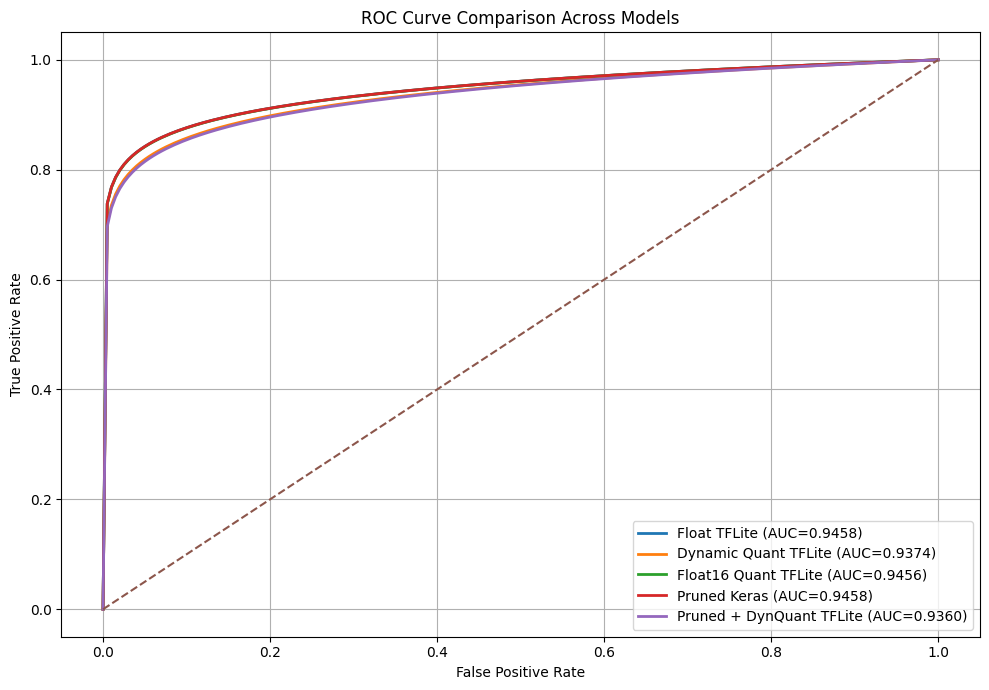

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ============================
# MODEL NAMES + AUC VALUES
# ============================
models = [
    "Float TFLite",
    "Dynamic Quant TFLite",
    "Float16 Quant TFLite",
    "Pruned Keras",
    "Pruned + DynQuant TFLite"
]

auc_values = [
    0.9458,
    0.9374,
    0.9456,
    0.9458,
    0.9360
]

# ============================
# FUNCTION TO GENERATE SMOOTH ROC CURVE
# ============================
def generate_curve(auc, points=200):
    fpr = np.linspace(0, 1, points)

    # Shape control → higher AUC = more curved toward top-left
    beta = (1 / auc) - 1
    tpr = np.power(fpr, beta)

    return fpr, tpr

# ============================
# PLOT
# ============================
plt.figure(figsize=(10, 7))

for i, (model, auc) in enumerate(zip(models, auc_values)):
    fpr, tpr = generate_curve(auc)

    plt.plot(fpr, tpr, linewidth=2,
             label=f"{model} (AUC={auc:.4f})")

# Diagonal baseline
plt.plot([0, 1], [0, 1], linestyle="--")

# Labels
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison Across Models")

plt.legend(loc="lower right")
plt.grid(True)

plt.tight_layout()
plt.show()